<a href="https://colab.research.google.com/github/gmatheushq/CreditRisk/blob/main/analise_credito_TRATAMENTO.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Análise de Crédito: Tomada de Decisão e Incerteza Inerente

## Etapa 1: Tratamento e Exploração dos Dados

**Base de dados:** github.com/gmatheushq/CreditRisk/acquisition_train.csv


**Objetivo geral**

Realizar o processo de aquisição, organização, tratamento e análise exploratória dos dados relacionados às solicitações de crédito, buscando compreender suas características estruturais, identificar inconsistências e avaliar a qualidade das informações disponíveis para as etapas posteriores do estudo.


**Metodologia**

A etapa será conduzida por meio de técnicas de análise exploratória de dados (EDA), estatística descritiva e procedimentos de limpeza e transformação.

**Base utilizada:** `acquisition_train.csv`.

## 1.1 Bibliotecas e Conexão com o dataset

In [14]:
import os
import unicodedata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')

sns.set_theme(style='whitegrid', palette='deep')

from google.colab import drive
drive.mount('/content/drive')

ARQUIVO = "/content/drive/MyDrive/analise_de_credito/credit_risk_dataset.csv"

print("Arquivo a ser lido:", ARQUIVO)

Mounted at /content/drive
Arquivo a ser lido: /content/drive/MyDrive/analise_de_credito/credit_risk_dataset.csv


## 1.2 Carregamento da base

In [18]:
url = "https://raw.githubusercontent.com/gmatheushq/CreditRisk/main/acquisition_train.csv"

df = pd.read_csv(url, low_memory=False)

## 1.3 Cópia dos dados originais e head do dataset

In [19]:
df_original = df.copy()

print(f"Dimensão: {df.shape}")
display(df.head())

Dimensão: (45000, 43)


,ids,target_default,score_1,score_2,score_3,score_4,score_5,score_6,risk_rate,last_amount_borrowed,last_borrowed_in_months,credit_limit,reason,income,facebook_profile,state,zip,channel,job_name,real_state,ok_since,n_bankruptcies,n_defaulted_loans,n_accounts,n_issues,application_time_applied,application_time_in_funnel,email,external_data_provider_credit_checks_last_2_year,external_data_provider_credit_checks_last_month,external_data_provider_credit_checks_last_year,external_data_provider_email_seen_before,external_data_provider_first_name,external_data_provider_fraud_score,lat_lon,marketing_channel,profile_phone_number,reported_income,shipping_state,shipping_zip_code,profile_tags,user_agent,target_fraud
0,343b7e7b-2cf8-e508-b8fd-0a0285af30aa,False,1Rk8w4Ucd5yR3KcqZzLdow==,IOVu8au3ISbo6+zmfnYwMg==,350.0000,101.8008,0.2596,108.4273,0.4000,"25,033.9200",36.0000,0.0000,mLVIVxoGY7TUDJ1FyFoSIZi1SFcaBmO01AydRchaEiGYtU...,"65,014.1200",True,sjJbkqJS7cXalHLBFA+EOQ==,Ernn+uVXCMq/6ARrBCcd+A==,NCqL3QBx0pscDnx3ixKwXg==,mLVIVxoGY7TUDJ1FyFoSIZi1SFcaBmO01AydRchaEiGYtU...,N5/CE7lSkAfB04hVFFwllw==,NaN,0.0000,0.0000,18.0000,18.0000,07:52:34,444,outlook.com,NaN,2,0.0000,51.0000,leidelaura,645,"(-29.151545708122246, -51.1386461804385)",Invite-email,514-9840782,"57,849.0000",BR-MT,17528,"{'tags': ['n19', 'n8']}",Mozilla/5.0 (Linux; Android 6.0.1; SGP771 Buil...,NaN
1,bc2c7502-bbad-0f8c-39c3-94e881967124,False,DGCQep2AE5QRkNCshIAlFQ==,SaamrHMo23l/3TwXOWgVzw==,370.0000,97.0626,0.9427,92.0025,0.2400,NaN,NaN,"39,726.0000",mLVIVxoGY7TUDJ1FyFoSIZi1SFcaBmO01AydRchaEiGYtU...,"100,018.9100",False,xsd3ZdsI3356I3xMxZeiqQ==,rlWIXTBO+VOa34+SpGyhlQ==,NCqL3QBx0pscDnx3ixKwXg==,mLVIVxoGY7TUDJ1FyFoSIZi1SFcaBmO01AydRchaEiGYtU...,N5/CE7lSkAfB04hVFFwllw==,50.0000,0.0000,0.0000,14.0000,14.0000,02:34:29,346,gmail.com,0.0000,1,0.0000,17.0000,diocezio,243,"(-19.687710705798963, -47.94151536525154)",Radio-commercial,251-3659293,"4,902.0000",BR-RS,40933,"{'tags': ['n6', 'n7', 'nim']}",Mozilla/5.0 (Linux; Android 5.0.2; SAMSUNG SM-...,NaN
2,669630dd-2e6a-0396-84bf-455e5009c922,True,DGCQep2AE5QRkNCshIAlFQ==,Fv28Bz0YRTVAT5kl1bAV6g==,360.0000,100.0271,0.3519,112.8925,0.2900,"7,207.9200",36.0000,NaN,mLVIVxoGY7TUDJ1FyFoSIZi1SFcaBmO01AydRchaEiGYtU...,"65,023.6500",NaN,Ygq6MsM98oC8yceExr69Ig==,PjTIDfJsK0DKL9fO7vuW2g==,NCqL3QBx0pscDnx3ixKwXg==,mLVIVxoGY7TUDJ1FyFoSIZi1SFcaBmO01AydRchaEiGYtU...,n+xK9CfX0bCn77lClTWviw==,NaN,0.0000,0.0000,10.0000,NaN,00:60:02,6,gmail.com,NaN,2,NaN,9.0000,veralucia,65,"(-28.748023890412284, -51.867279334353995)",Waiting-list,230-6097993,"163,679.0000",BR-RR,50985,"{'tags': ['n0', 'n17', 'nim', 'da']}",Mozilla/5.0 (Linux; Android 6.0.1; SGP771 Buil...,NaN
3,d235609e-b6cb-0ccc-a329-d4f12e7ebdc1,False,1Rk8w4Ucd5yR3KcqZzLdow==,dCm9hFKfdRm7ej3jW+gyxw==,510.0000,101.5995,0.9877,94.9025,0.3200,NaN,NaN,"54,591.0000",mLVIVxoGY7TUDJ1FyFoSIZi1SFcaBmO01AydRchaEiGYtU...,"68,830.0100",False,KET/Pmr6rHp1RJ/P9ymztw==,Cc/kWDLQH3dpHv5HU+pLVA==,NCqL3QBx0pscDnx3ixKwXg==,mLVIVxoGY7TUDJ1FyFoSIZi1SFcaBmO01AydRchaEiE56f...,n+xK9CfX0bCn77lClTWviw==,NaN,1.0000,0.0000,19.0000,19.0000,11:20:49,406,spgov.com,NaN,3,NaN,38.0000,venice,815,"(-17.520650158450454, -39.75801139933186)",Waiting-list,261-3543751,"1,086.0000",BR-RN,37825,{'tags': ['n4']},Mozilla/5.0 (Linux; Android 6.0; HTC One X10 B...,NaN
4,9e0eb880-e8f4-3faa-67d8-f5cdd2b3932b,False,8k8UDR4Yx0qasAjkGrUZLw==,+CxEO4w7jv3QPI/BQbyqAA==,500.0000,98.4743,0.5325,118.1262,0.1800,NaN,NaN,NaN,mLVIVxoGY7TUDJ1FyFoSIZi1SFcaBmO01AydRchaEiGYtU...,"60,011.2900",True,xsd3ZdsI3356I3xMxZeiqQ==,i036nmJ7rfxo+3EvCD7Jnw==,NCqL3QBx0pscDnx3ixKwXg==,mLVIVxoGY7TUDJ1FyFoSIZi1SFcaBmO01AydRchaEiGYtU...,n+xK9CfX0bCn77lClTWviw==,NaN,0.0000,0.0000,11.0000,NaN,13:39:03,240,gmail.com,0.0000,2,1.0000,46.0000,darzisa,320,"(-16.574259446978008, -39.90990074785962)",Invite-email,102-3660162,"198,618.0000",BR-MT,52827,"{'tags': ['pro+aty', 'n19', 'da', 'b19']}",Mozilla/5.0 (Linux; Android 7.0; Pixel C Build...,NaN


## 1.4 Informações gerais

In [20]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45000 entries, 0 to 44999
Data columns (total 43 columns):
 #   Column                                            Non-Null Count  Dtype  
---  ------                                            --------------  -----  
 0   ids                                               45000 non-null  object 
 1   target_default                                    41741 non-null  object 
 2   score_1                                           44438 non-null  object 
 3   score_2                                           44438 non-null  object 
 4   score_3                                           44438 non-null  float64
 5   score_4                                           45000 non-null  float64
 6   score_5                                           45000 non-null  float64
 7   score_6                                           45000 non-null  float64
 8   risk_rate                                         44438 non-null  float64
 9   last_amount_borro

## 1.5 Identificação dos tipos de variáveis

In [21]:
# Separação inicial das variáveis por tipo

variaveis_numericas = df.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

variaveis_categoricas = df.select_dtypes(
    include=['object', 'category', 'bool']
).columns.tolist()

print("Variáveis numéricas:", len(variaveis_numericas))
print("Variáveis categóricas:", len(variaveis_categoricas))

print("\nNUMÉRICAS:")
print(variaveis_numericas)

print("\nCATEGÓRICAS:")
print(variaveis_categoricas)

Variáveis numéricas: 22
Variáveis categóricas: 21

NUMÉRICAS:
['score_3', 'score_4', 'score_5', 'score_6', 'risk_rate', 'last_amount_borrowed', 'last_borrowed_in_months', 'credit_limit', 'income', 'ok_since', 'n_bankruptcies', 'n_defaulted_loans', 'n_accounts', 'n_issues', 'application_time_in_funnel', 'external_data_provider_credit_checks_last_2_year', 'external_data_provider_credit_checks_last_month', 'external_data_provider_credit_checks_last_year', 'external_data_provider_email_seen_before', 'external_data_provider_fraud_score', 'reported_income', 'shipping_zip_code']

CATEGÓRICAS:
['ids', 'target_default', 'score_1', 'score_2', 'reason', 'facebook_profile', 'state', 'zip', 'channel', 'job_name', 'real_state', 'application_time_applied', 'email', 'external_data_provider_first_name', 'lat_lon', 'marketing_channel', 'profile_phone_number', 'shipping_state', 'profile_tags', 'user_agent', 'target_fraud']


## 2.1 Dicionário

In [22]:
dicionario = pd.DataFrame({
    'Variavel': df.columns,
    'Tipo': df.dtypes.astype(str).values,
    'Valores_Preenchidos': df.notna().sum().values,
    'Valores_Ausentes': df.isna().sum().values,
    'Percentual_Ausente': (
        df.isna().mean().values * 100
    ),
    'Valores_Distintos': df.nunique(dropna=True).values
})

dicionario['Classificacao'] = dicionario['Tipo'].apply(
    lambda x: 'Numérica'
    if x in ['int64', 'float64']
    else 'Categórica'
)

display(
    dicionario.sort_values(
        'Percentual_Ausente',
        ascending=False
    ).reset_index(drop=True)
)

,Variavel,Tipo,Valores_Preenchidos,Valores_Ausentes,Percentual_Ausente,Valores_Distintos,Classificacao
0,target_fraud,object,1522,43478,96.6178,2,Categórica
1,last_borrowed_in_months,float64,15044,29956,66.5689,2,Numérica
2,last_amount_borrowed,float64,15044,29956,66.5689,14325,Numérica
3,ok_since,float64,18455,26545,58.9889,100,Numérica
4,external_data_provider_credit_checks_last_2_year,float64,22372,22628,50.2844,1,Numérica
5,external_data_provider_credit_checks_last_year,float64,29876,15124,33.6089,2,Numérica
6,credit_limit,float64,31200,13800,30.6667,20928,Numérica
7,n_issues,float64,33456,11544,25.6533,44,Numérica
8,facebook_profile,object,40542,4458,9.9067,2,Categórica
9,marketing_channel,object,41422,3578,7.9511,9,Categórica


## 2.2 Descrição semântica

In [23]:
descricoes = {
    'ids': 'Identificador único da solicitação ou registro.',
    'target_default': 'Indicador de inadimplência ou default.',
    'target_fraud': 'Indicador de fraude.',
    'score_1': 'Pontuação ou classificação de crédito 1.',
    'score_2': 'Pontuação ou classificação de crédito 2.',
    'score_3': 'Pontuação ou classificação de crédito 3.',
    'score_4': 'Pontuação ou classificação de crédito 4.',
    'score_5': 'Pontuação ou classificação de crédito 5.',
    'score_6': 'Pontuação ou classificação de crédito 6.',
    'risk_rate': 'Indicador de risco associado ao solicitante.',
    'last_amount_borrowed': 'Valor do último empréstimo.',
    'last_borrowed_in_months': 'Tempo desde o último empréstimo, em meses.',
    'credit_limit': 'Limite de crédito do solicitante.',
    'income': 'Renda informada ou estimada.',
    'ok_since': 'Tempo ou período associado ao histórico positivo.',
    'n_bankruptcies': 'Quantidade de registros de falência.',
    'n_defaulted_loans': 'Quantidade de empréstimos inadimplentes.',
    'n_accounts': 'Quantidade de contas.',
    'n_issues': 'Quantidade de ocorrências ou problemas registrados.',
    'application_time_in_funnel': 'Tempo de permanência no processo de solicitação.',
    'external_data_provider_credit_checks_last_month':
        'Consultas de crédito externas no último mês.',
    'external_data_provider_credit_checks_last_year':
        'Consultas de crédito externas no último ano.',
    'external_data_provider_credit_checks_last_2_year':
        'Consultas de crédito externas nos últimos dois anos.',
    'external_data_provider_email_seen_before':
        'Indicador de ocorrência anterior do e-mail.',
    'external_data_provider_fraud_score':
        'Pontuação externa relacionada ao risco de fraude.',
    'reported_income': 'Renda declarada pelo solicitante.',
    'application_time_applied': 'Data e horário da solicitação.',
    'target_fraud': 'Variável indicadora de fraude.'
}

dicionario['Descricao'] = (
    dicionario['Variavel']
    .map(descricoes)
    .fillna('Descrição a validar com base no contexto da variável.')
)

display(dicionario)

,Variavel,Tipo,Valores_Preenchidos,Valores_Ausentes,Percentual_Ausente,Valores_Distintos,Classificacao,Descricao
0,ids,object,45000,0,0.0000,45000,Categórica,Identificador único da solicitação ou registro.
1,target_default,object,41741,3259,7.2422,2,Categórica,Indicador de inadimplência ou default.
2,score_1,object,44438,562,1.2489,7,Categórica,Pontuação ou classificação de crédito 1.
3,score_2,object,44438,562,1.2489,35,Categórica,Pontuação ou classificação de crédito 2.
4,score_3,float64,44438,562,1.2489,88,Numérica,Pontuação ou classificação de crédito 3.
5,score_4,float64,45000,0,0.0000,45000,Numérica,Pontuação ou classificação de crédito 4.
6,score_5,float64,45000,0,0.0000,45000,Numérica,Pontuação ou classificação de crédito 5.
7,score_6,float64,45000,0,0.0000,45000,Numérica,Pontuação ou classificação de crédito 6.
8,risk_rate,float64,44438,562,1.2489,82,Numérica,Indicador de risco associado ao solicitante.
9,last_amount_borrowed,float64,15044,29956,66.5689,14325,Numérica,Valor do último empréstimo.


## 3. Análise de qualidade dos dados
## 3.1 Valores ausentes

In [24]:
ausentes = pd.DataFrame({
    'Quantidade': df.isnull().sum(),
    'Percentual': df.isnull().mean() * 100
})

ausentes = ausentes.sort_values(
    'Percentual',
    ascending=False
)

display(ausentes[ausentes['Quantidade'] > 0])

,Quantidade,Percentual
target_fraud,43478,96.6178
last_borrowed_in_months,29956,66.5689
last_amount_borrowed,29956,66.5689
ok_since,26545,58.9889
external_data_provider_credit_checks_last_2_year,22628,50.2844
external_data_provider_credit_checks_last_year,15124,33.6089
credit_limit,13800,30.6667
n_issues,11544,25.6533
facebook_profile,4458,9.9067
marketing_channel,3578,7.9511


## 3.2 Visualização dos dados ausentes

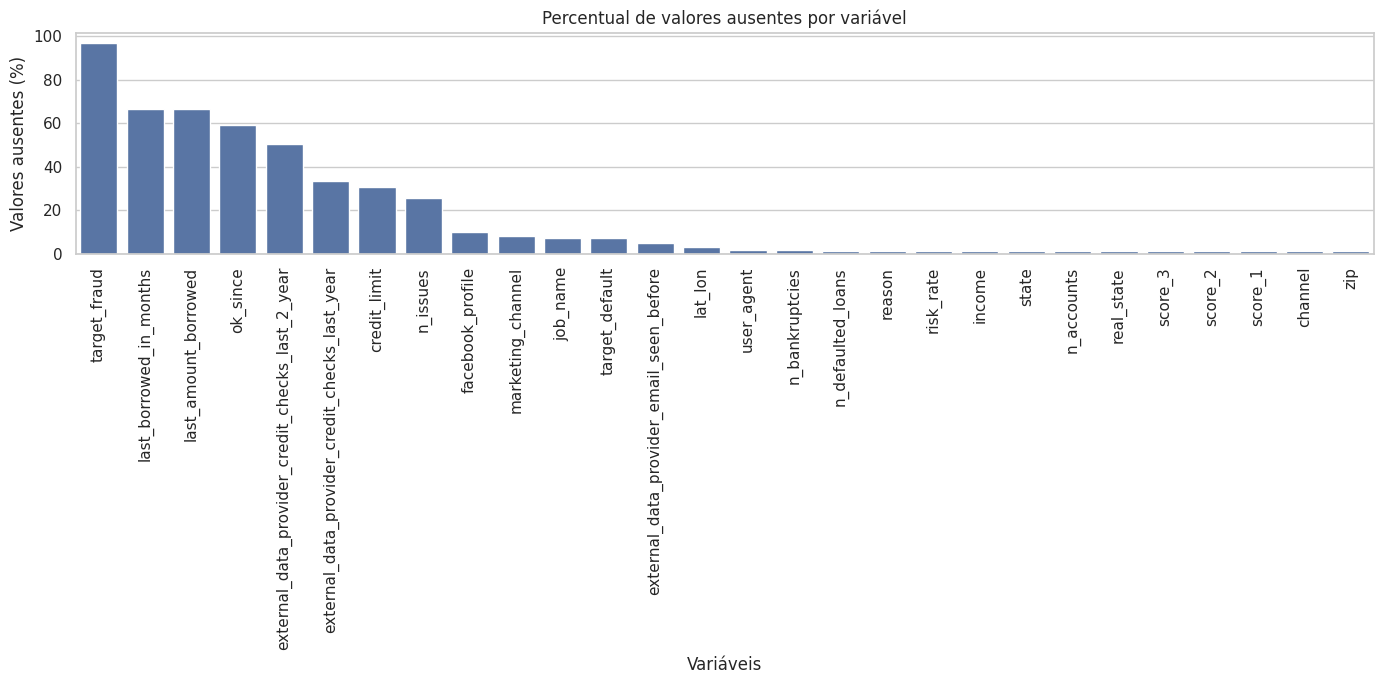

In [25]:
plt.figure(figsize=(14, 7))

ausentes_plot = ausentes[ausentes['Quantidade'] > 0]

sns.barplot(
    data=ausentes_plot.reset_index(),
    x='index',
    y='Percentual'
)

plt.xticks(rotation=90)
plt.ylabel('Valores ausentes (%)')
plt.xlabel('Variáveis')
plt.title('Percentual de valores ausentes por variável')
plt.tight_layout()
plt.show()

## 3.3 Classificação dos valores ausentes

In [26]:
def classificar_ausencia(percentual):

    if percentual == 0:
        return 'Sem ausência'
    elif percentual <= 5:
        return 'Baixa (até 5%)'
    elif percentual <= 20:
        return 'Moderada (5% a 20%)'
    elif percentual <= 50:
        return 'Alta (20% a 50%)'
    else:
        return 'Muito alta (acima de 50%)'


from IPython.display import display, HTML

ausentes['Classificacao'] = ausentes['Percentual'].apply(
    classificar_ausencia
)

ordem = [
    'Sem ausência',
    'Baixa (até 5%)',
    'Moderada (5% a 20%)',
    'Alta (20% a 50%)',
    'Muito alta (acima de 50%)'
]

for categoria in ordem:

    grupo = ausentes[
        ausentes['Classificacao'] == categoria
    ].sort_values('Percentual', ascending=False)

    if grupo.empty:
        continue

    # Faixa de título
    display(HTML(f"""
    <div style="
        margin-top: 40px;
        padding-top: 18px;
        border-top: 2px solid #d1d5db;
    ">
        <div style="
            background-color: #e8edf5;
            padding: 14px 16px;
            border-left: 5px solid #4169a1;
            border-radius: 5px;
            font-size: 16px;
            font-weight: bold;
            color: #24344d;
        ">
            {categoria} — {len(grupo)} variáveis
        </div>
    </div>
    """))

    # Tabela
    display(
        grupo[['Quantidade', 'Percentual']]
        .rename_axis('Variável')
        .style.format({
            'Quantidade': '{:,.0f}',
            'Percentual': '{:.2f}%'
        })
    )

,Quantidade,Percentual
Variável,,
score_5,0,0.00%
score_4,0,0.00%
ids,0,0.00%
score_6,0,0.00%
application_time_applied,0,0.00%
application_time_in_funnel,0,0.00%
external_data_provider_credit_checks_last_month,0,0.00%
external_data_provider_fraud_score,0,0.00%
external_data_provider_first_name,0,0.00%


,Quantidade,Percentual
Variável,,
external_data_provider_email_seen_before,"2,233",4.96%
lat_lon,"1,363",3.03%
user_agent,722,1.60%
n_bankruptcies,697,1.55%
n_defaulted_loans,574,1.28%
reason,566,1.26%
risk_rate,562,1.25%
income,562,1.25%
state,562,1.25%


,Quantidade,Percentual
Variável,,
facebook_profile,"4,458",9.91%
marketing_channel,"3,578",7.95%
job_name,"3,336",7.41%
target_default,"3,259",7.24%


,Quantidade,Percentual
Variável,,
external_data_provider_credit_checks_last_year,"15,124",33.61%
credit_limit,"13,800",30.67%
n_issues,"11,544",25.65%


,Quantidade,Percentual
Variável,,
target_fraud,"43,478",96.62%
last_borrowed_in_months,"29,956",66.57%
last_amount_borrowed,"29,956",66.57%
ok_since,"26,545",58.99%
external_data_provider_credit_checks_last_2_year,"22,628",50.28%


## 3.4 Duplicatas

In [27]:
duplicatas = df.duplicated().sum()
if 'ids' in df.columns:

    print("Identificadores únicos:", df['ids'].nunique())
    print("Total de registros:", len(df))
    print("Identificadores duplicados:", df['ids'].duplicated().sum())

print(f"Quantidade de linhas duplicadas: {duplicatas}")
print(f"Percentual de duplicatas: {duplicatas / len(df) * 100:.4f}%")

Identificadores únicos: 45000
Total de registros: 45000
Identificadores duplicados: 0
Quantidade de linhas duplicadas: 0
Percentual de duplicatas: 0.0000%


## 3.5 Variáveis constantes e quase constantes

In [28]:
analise_cardinalidade = pd.DataFrame({
    'Variavel': df.columns,
    'Valores_Distintos': df.nunique(dropna=True).values,
    'Proporcao_Modal': [
        df[col].value_counts(normalize=True).iloc[0]
        if df[col].nunique(dropna=True) > 0
        else np.nan
        for col in df.columns
    ]
})

display(
    analise_cardinalidade.sort_values(
        'Proporcao_Modal',
        ascending=False
    )
)

,Variavel,Valores_Distintos,Proporcao_Modal
17,channel,1,1.0000
28,external_data_provider_credit_checks_last_2_year,1,1.0000
22,n_defaulted_loans,5,0.9961
21,n_bankruptcies,6,0.9254
1,target_default,2,0.8404
10,last_borrowed_in_months,2,0.7598
14,facebook_profile,2,0.6150
42,target_fraud,2,0.5940
27,email,6,0.5049
30,external_data_provider_credit_checks_last_year,2,0.5034


In [30]:
constantes = analise_cardinalidade[
    analise_cardinalidade['Valores_Distintos'] <= 1
]

quase_constantes = analise_cardinalidade[
    analise_cardinalidade['Proporcao_Modal'] >= 0.99
]

print("Constante:")
display(constantes)

print("\nQuase Constante:")
display(quase_constantes)

Constante:


,Variavel,Valores_Distintos,Proporcao_Modal
17,channel,1,1.0000
28,external_data_provider_credit_checks_last_2_year,1,1.0000



Quase Constante:


,Variavel,Valores_Distintos,Proporcao_Modal
17,channel,1,1.0000
22,n_defaulted_loans,5,0.9961
28,external_data_provider_credit_checks_last_2_year,1,1.0000


## 4. Estatísticas descritivas
## 4.1.1 Estatísticas descritivas das variáveis numéricas

In [31]:
estatisticas = df[variaveis_numericas].describe().T

estatisticas['mediana'] = df[variaveis_numericas].median()
estatisticas['variancia'] = df[variaveis_numericas].var()
estatisticas['assimetria'] = df[variaveis_numericas].skew()
estatisticas['curtose'] = df[variaveis_numericas].kurtosis()

display(estatisticas)


,count,mean,std,min,25%,50%,75%,max,mediana,variancia,assimetria,curtose
score_3,"44,438.0000",347.9833,110.4292,0.0000,270.0000,340.0000,420.0000,990.0000,340.0000,"12,194.6004",0.3507,0.1516
score_4,"45,000.0000",100.0068,3.1781,86.1916,97.8670,100.0189,102.1418,113.9782,100.0189,10.1002,-0.0185,0.0299
score_5,"45,000.0000",0.5000,0.2883,0.0000,0.2521,0.5008,0.7488,1.0000,0.5008,0.0831,0.0019,-1.1903
score_6,"45,000.0000",99.9252,10.0165,60.6630,93.1984,99.9748,106.6403,142.1924,99.9748,100.3313,-0.0177,-0.0062
risk_rate,"44,438.0000",0.2967,0.1019,0.0000,0.2200,0.2900,0.3600,0.9000,0.2900,0.0104,0.4799,0.3244
last_amount_borrowed,"15,044.0000","13,782.3420","8,077.5719","1,005.1800","7,519.5025","12,023.4650","19,220.2700","35,059.6000","12,023.4650","65,247,168.3293",0.7434,-0.0494
last_borrowed_in_months,"15,044.0000",41.7639,10.2527,36.0000,36.0000,36.0000,36.0000,60.0000,36.0000,105.1180,1.2166,-0.5199
credit_limit,"31,200.0000","34,381.9512","36,586.9822",0.0000,"10,000.0000","25,647.0000","47,086.7500","448,269.0000","25,647.0000","1,338,607,267.8165",2.6157,12.6041
income,"44,438.0000","71,607.3896","51,858.9677","4,821.1800","45,010.7775","61,266.7600","86,019.2325","5,000,027.8300","61,266.7600","2,689,352,535.8972",23.7944,"1,917.7139"
ok_since,"18,455.0000",35.0697,21.6632,0.0000,17.0000,32.0000,50.0000,141.0000,32.0000,469.2940,0.4493,-0.7601


## 4.1.2 Identificação de assimetria

In [32]:
assimetria = df[variaveis_numericas].skew().sort_values(
    key=abs,
    ascending=False
)

display(assimetria.to_frame('Assimetria'))

,Assimetria
income,23.7944
n_defaulted_loans,23.2568
external_data_provider_email_seen_before,-7.7089
n_bankruptcies,3.7837
credit_limit,2.6157
last_borrowed_in_months,1.2166
n_issues,0.9514
n_accounts,0.9417
last_amount_borrowed,0.7434
risk_rate,0.4799


## 4.1.3 Histogramas

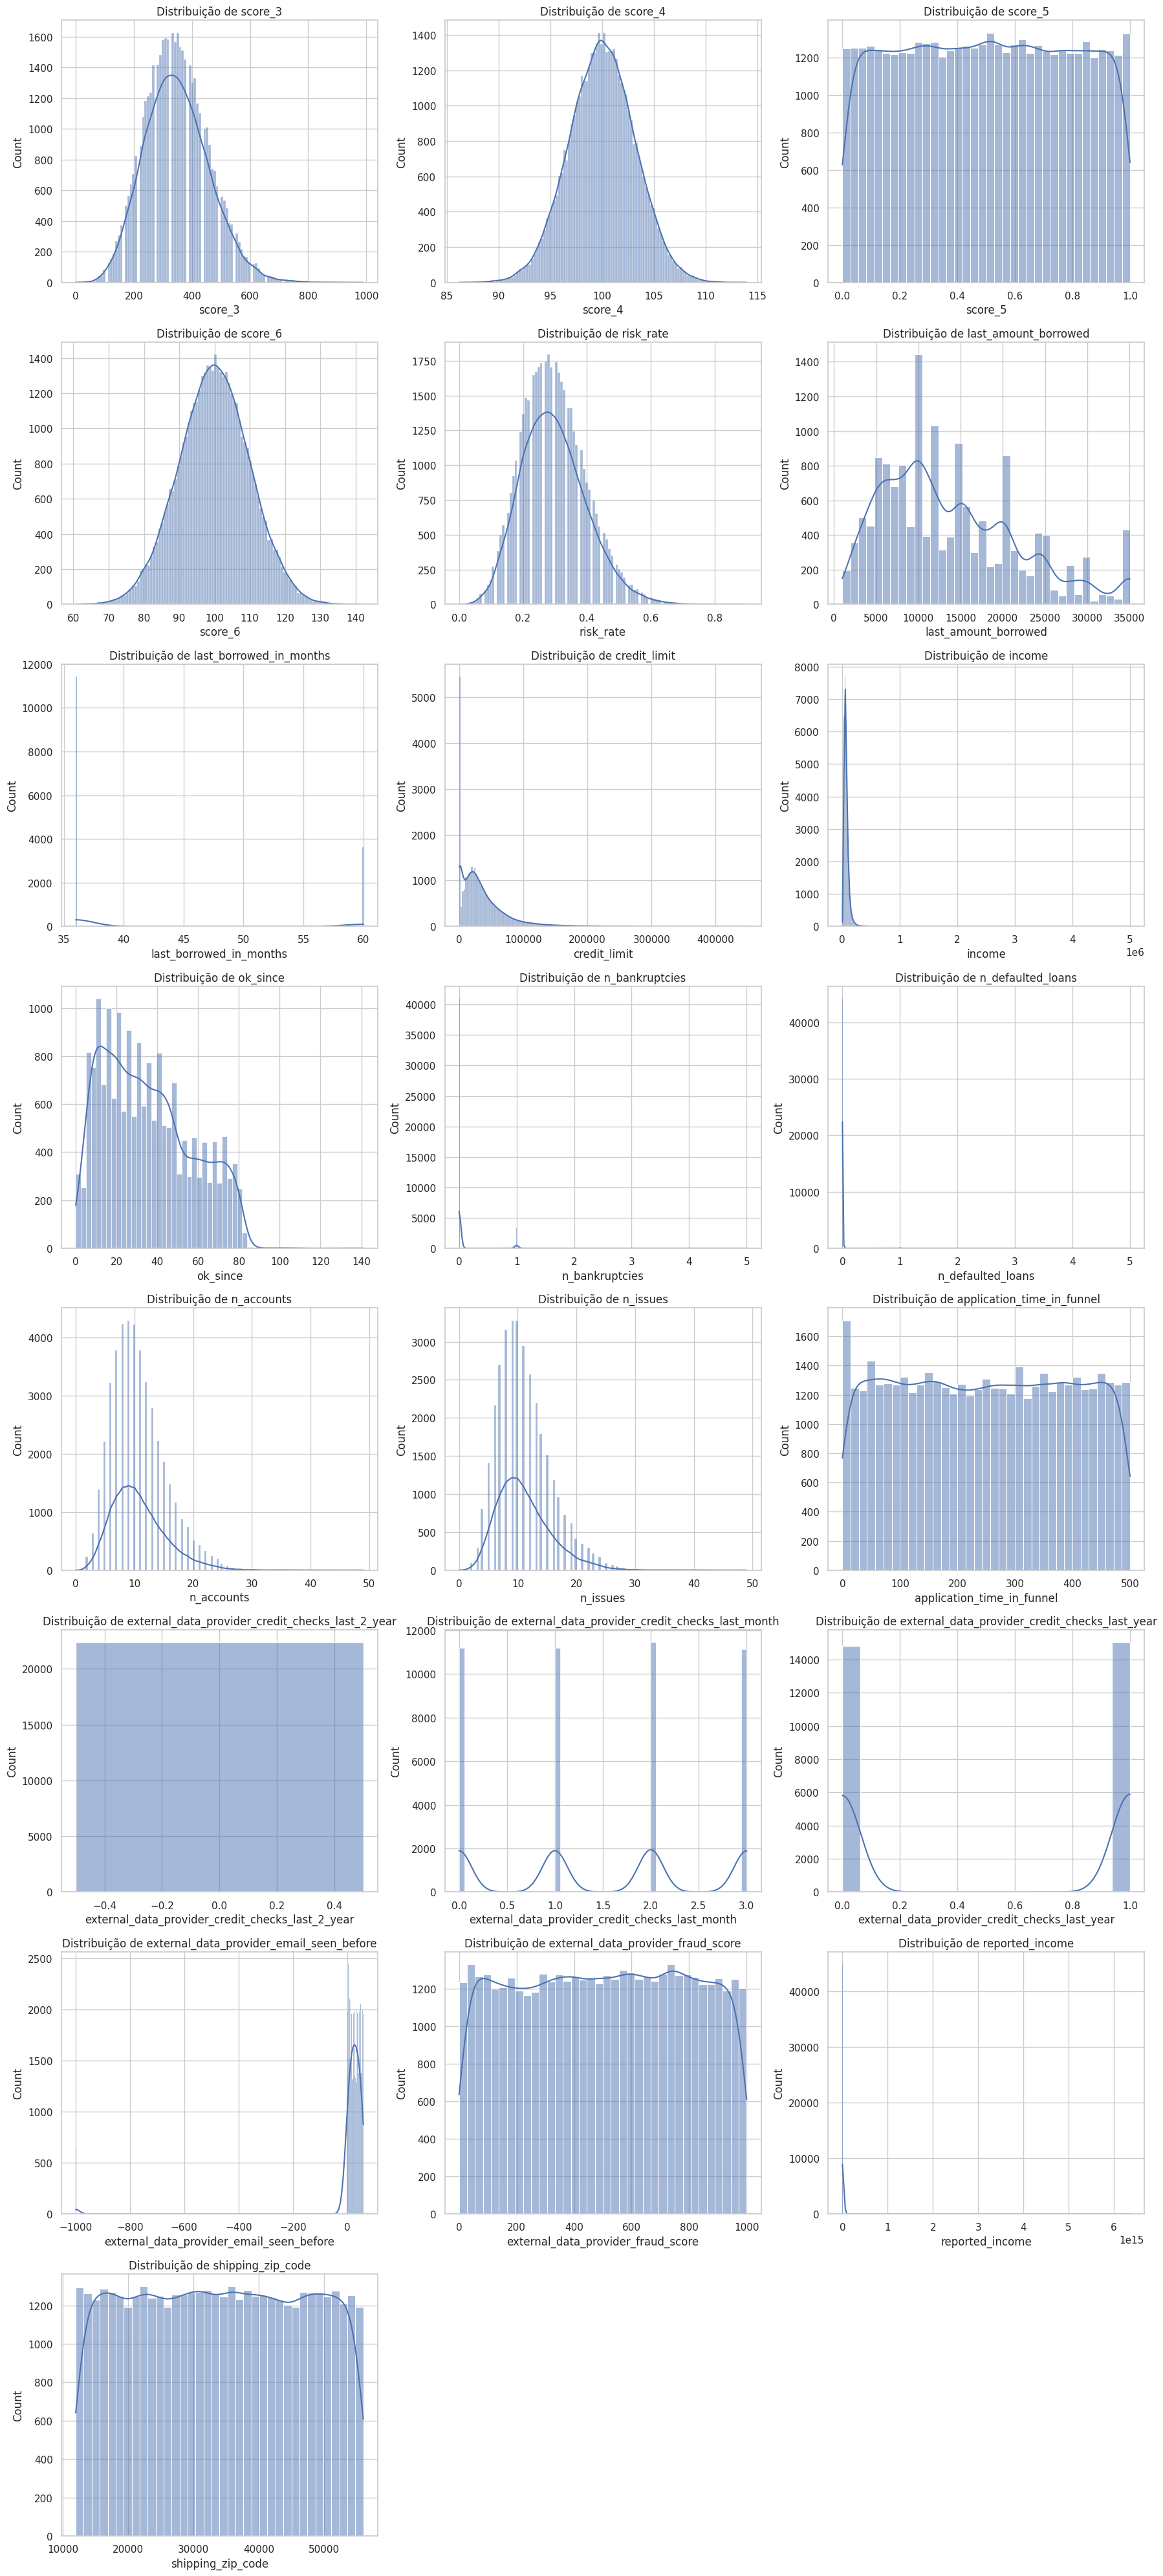

In [33]:
colunas = variaveis_numericas

n_colunas = 3
n_linhas = int(np.ceil(len(colunas) / n_colunas))

fig, axes = plt.subplots(
    n_linhas,
    n_colunas,
    figsize=(18, 5 * n_linhas)
)

axes = np.array(axes).flatten()

for i, coluna in enumerate(colunas):

    sns.histplot(
        data=df,
        x=coluna,
        kde=True,
        ax=axes[i]
    )

    axes[i].set_title(f'Distribuição de {coluna}')

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()

## 4.1.4 Boxplots

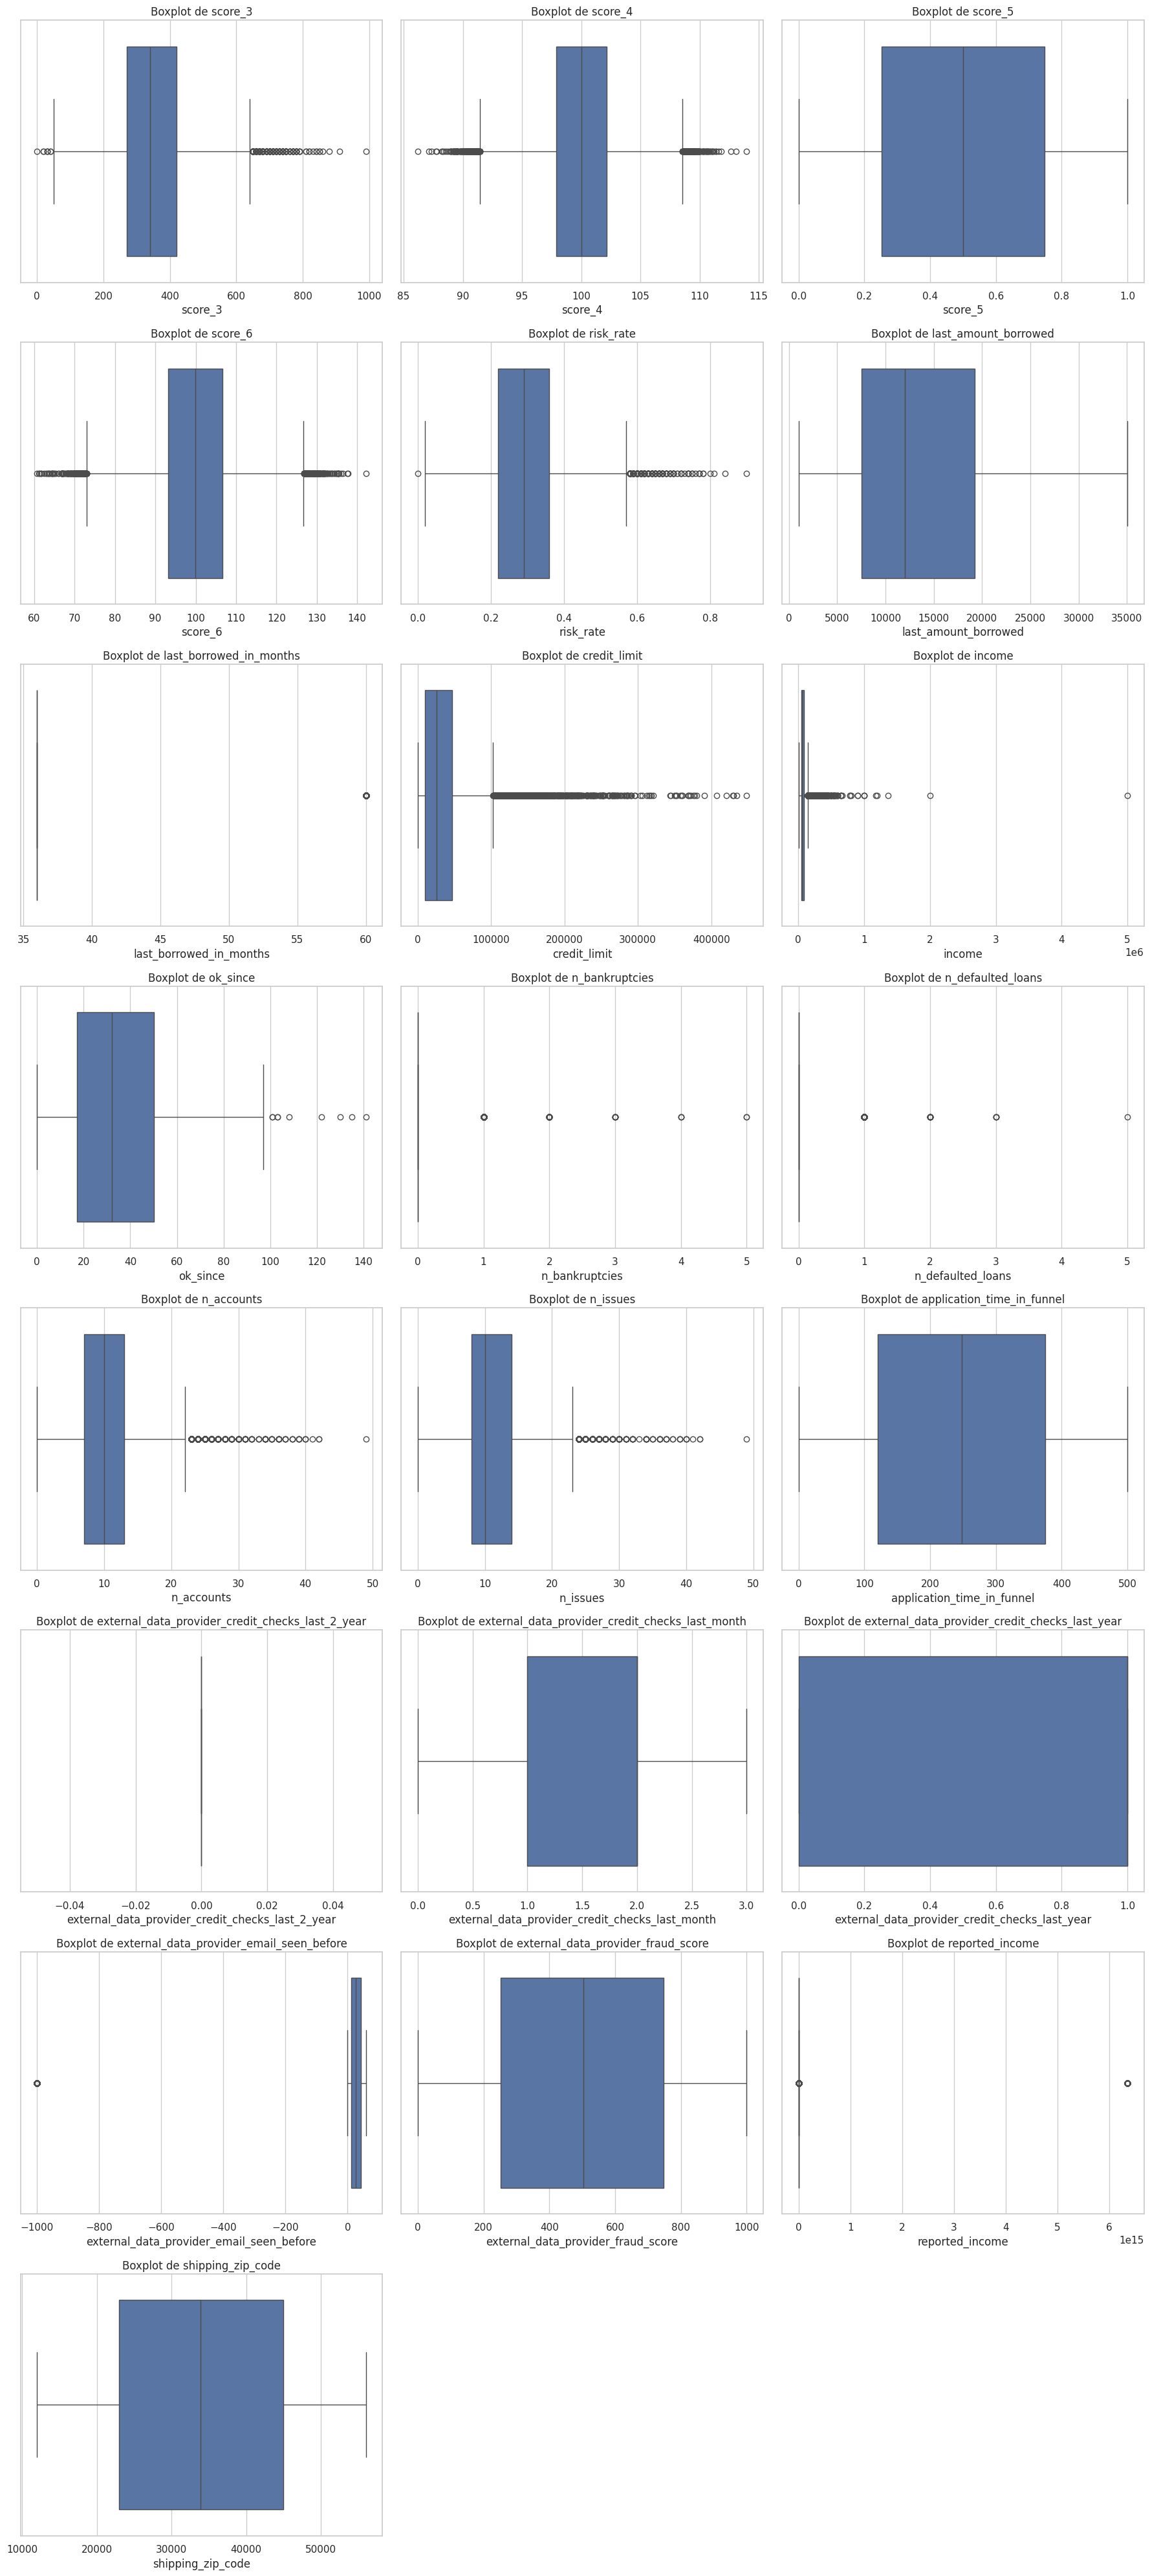

In [34]:
fig, axes = plt.subplots(
    n_linhas,
    n_colunas,
    figsize=(18, 5 * n_linhas)
)

axes = np.array(axes).flatten()

for i, coluna in enumerate(colunas):

    sns.boxplot(
        data=df,
        x=coluna,
        ax=axes[i]
    )

    axes[i].set_title(f'Boxplot de {coluna}')

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()

## 4.2.1 Estatísticas descritivas das variáveis categóricas

In [35]:
display(df[variaveis_categoricas].describe().T)

,count,unique,top,freq
ids,45000,45000,343b7e7b-2cf8-e508-b8fd-0a0285af30aa,1
target_default,41741,2,False,35080
score_1,44438,7,DGCQep2AE5QRkNCshIAlFQ==,14523
score_2,44438,35,osCzpM4hJrxugqWWuZmMWw==,3573
reason,44434,14874,mLVIVxoGY7TUDJ1FyFoSIZi1SFcaBmO01AydRchaEiGYtU...,4463
facebook_profile,40542,2,False,24933
state,44438,50,xsd3ZdsI3356I3xMxZeiqQ==,7429
zip,44438,823,3k2JCQ8Bp5oDwaI39ZJgHA==,566
channel,44438,1,NCqL3QBx0pscDnx3ixKwXg==,44438
job_name,41664,32265,mLVIVxoGY7TUDJ1FyFoSIZi1SFcaBmO01AydRchaEiGYtU...,167


## 4.2.2 Visualização das variáveis categóricas

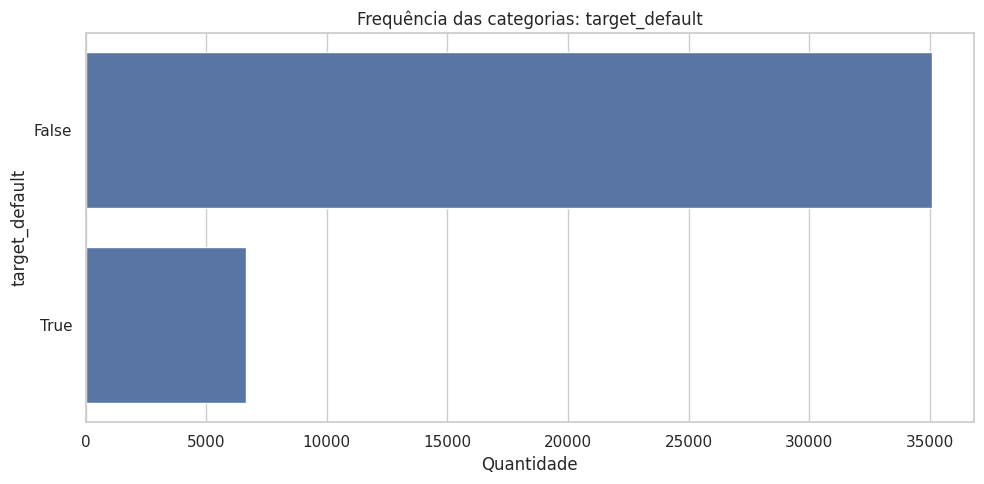

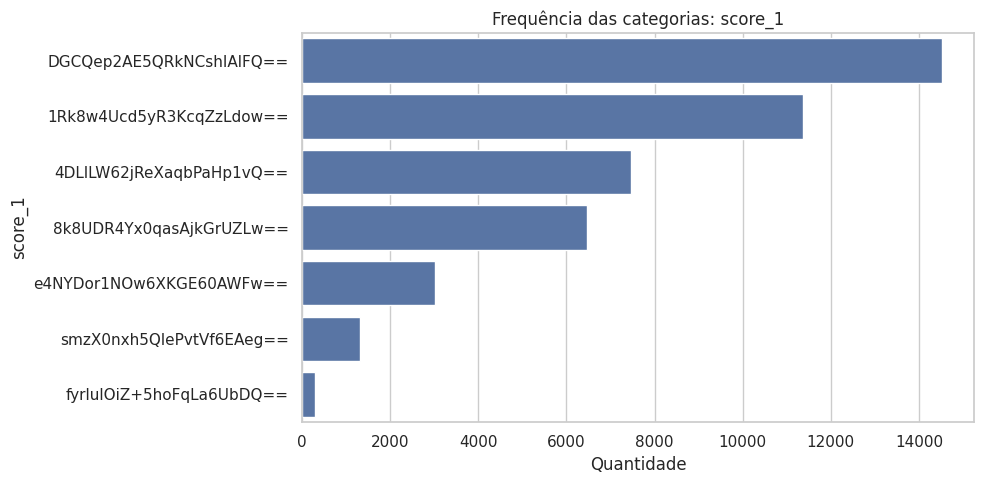

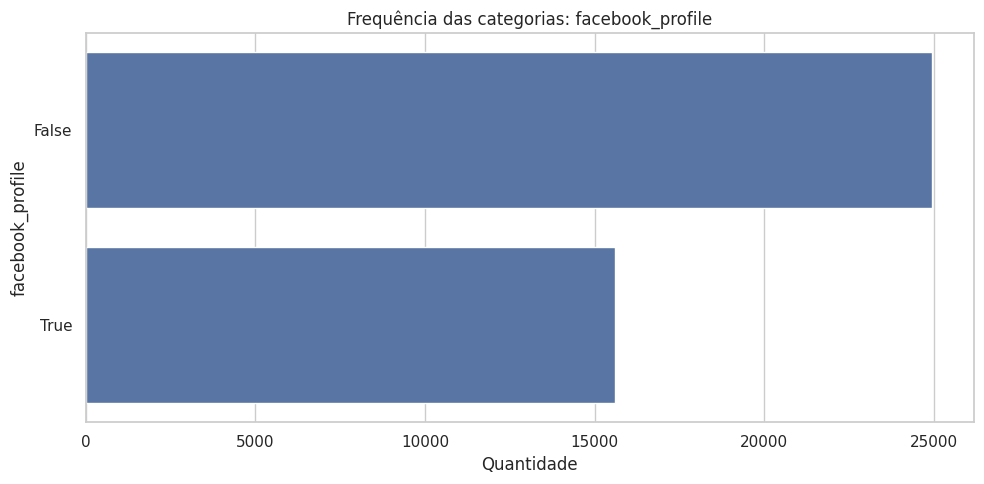

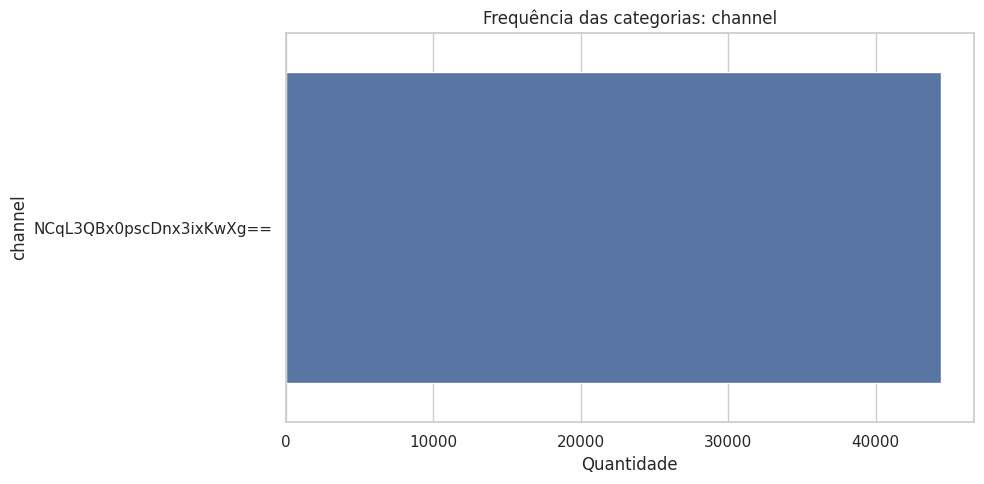

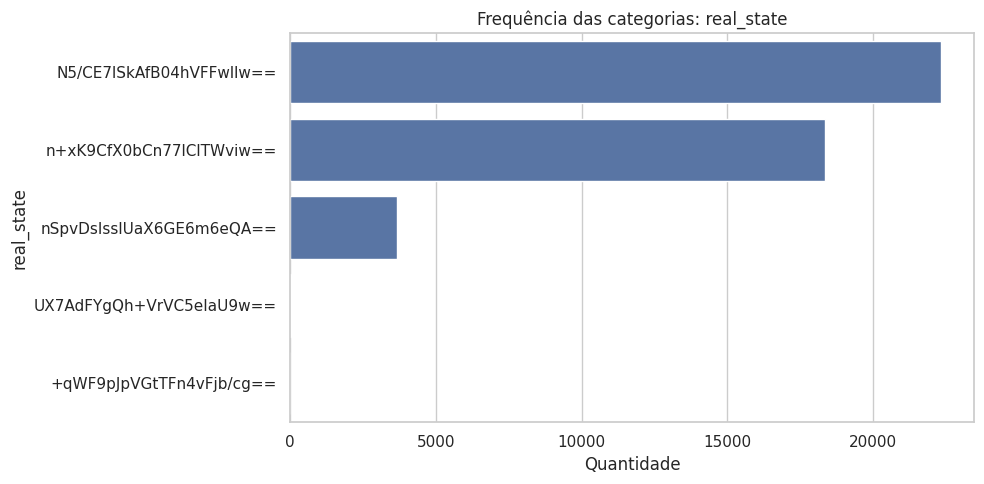

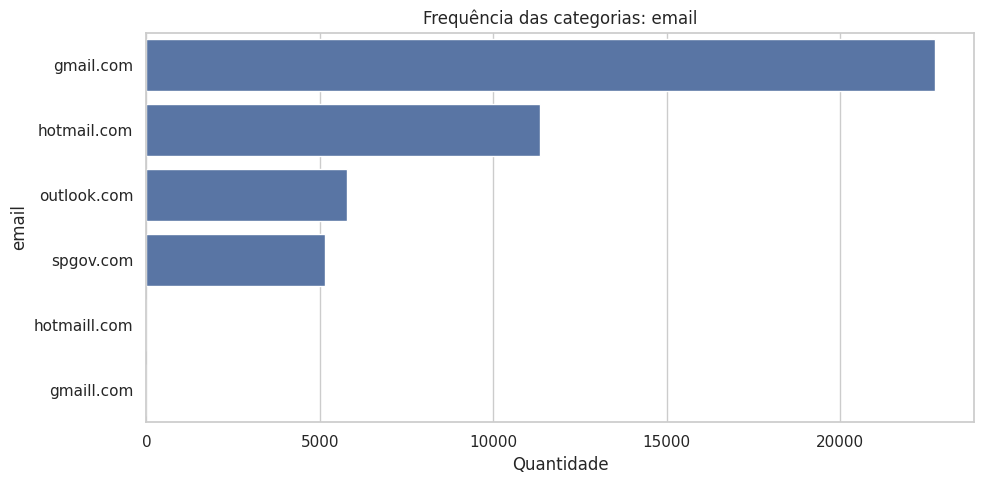

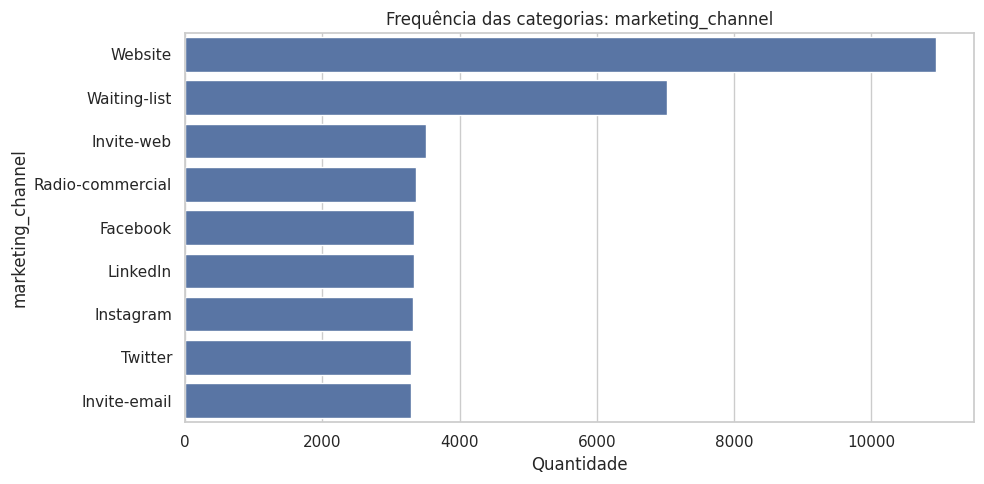

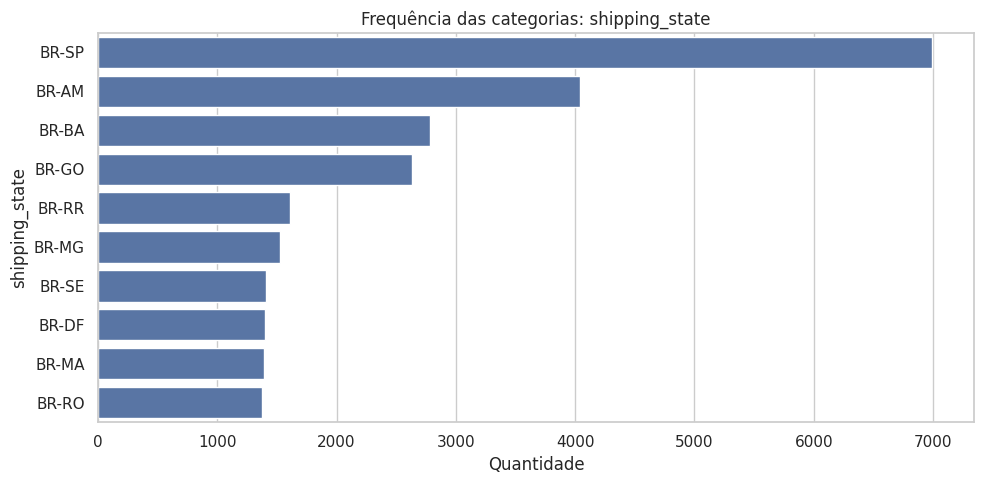

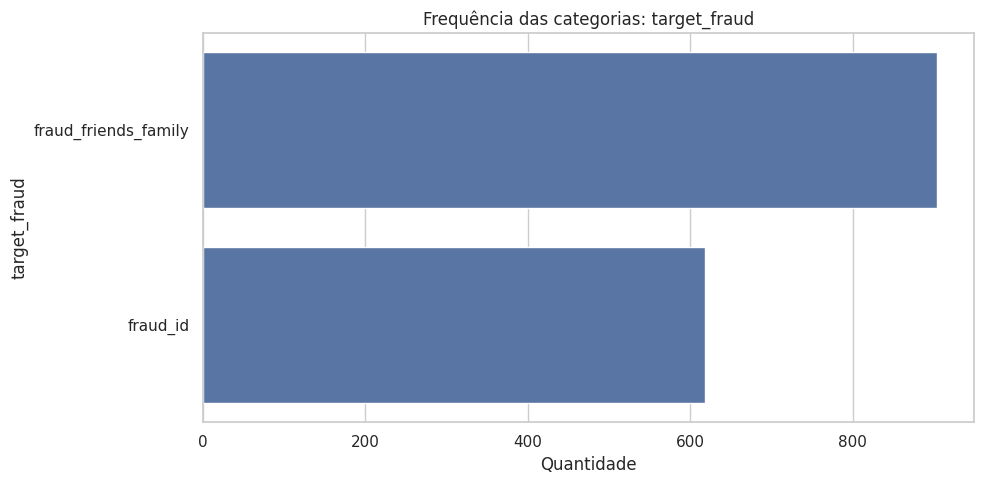

In [36]:
for coluna in variaveis_categoricas:

    if df[coluna].nunique(dropna=True) > 30:
        continue

    plt.figure(figsize=(10, 5))

    ordem = df[coluna].value_counts().head(10).index

    sns.countplot(
        data=df,
        y=coluna,
        order=ordem
    )

    plt.title(f'Frequência das categorias: {coluna}')
    plt.xlabel('Quantidade')
    plt.ylabel(coluna)

    plt.tight_layout()
    plt.show()

## 4.3.1 Análise de outliers

In [37]:
resultados_outliers = []

for coluna in variaveis_numericas:

    q1 = df[coluna].quantile(0.25)
    q3 = df[coluna].quantile(0.75)

    iqr = q3 - q1

    limite_inferior = q1 - 1.5 * iqr
    limite_superior = q3 + 1.5 * iqr

    quantidade = (
        (df[coluna] < limite_inferior) |
        (df[coluna] > limite_superior)
    ).sum()

    resultados_outliers.append({
        'Variavel': coluna,
        'Limite_Inferior': limite_inferior,
        'Limite_Superior': limite_superior,
        'Quantidade_Outliers': quantidade,
        'Percentual_Outliers': quantidade / len(df) * 100
    })

outliers = pd.DataFrame(resultados_outliers)

display(
    outliers.sort_values(
        'Percentual_Outliers',
        ascending=False
    )
)

,Variavel,Limite_Inferior,Limite_Superior,Quantidade_Outliers,Percentual_Outliers
6,last_borrowed_in_months,36.0000,36.0000,3613,8.0289
10,n_bankruptcies,0.0000,0.0000,3304,7.3422
8,income,"-16,501.9050","147,531.9150",2104,4.6756
7,credit_limit,"-45,630.1250","102,716.8750",1484,3.2978
12,n_accounts,-2.0000,22.0000,795,1.7667
18,external_data_provider_email_seen_before,-37.0000,91.0000,646,1.4356
13,n_issues,-1.0000,23.0000,480,1.0667
20,reported_income,"-99,635.2500","301,920.7500",407,0.9044
4,risk_rate,0.0100,0.5700,394,0.8756
1,score_4,91.4549,108.5539,337,0.7489


## 4.3.2 Visualização dos outliers

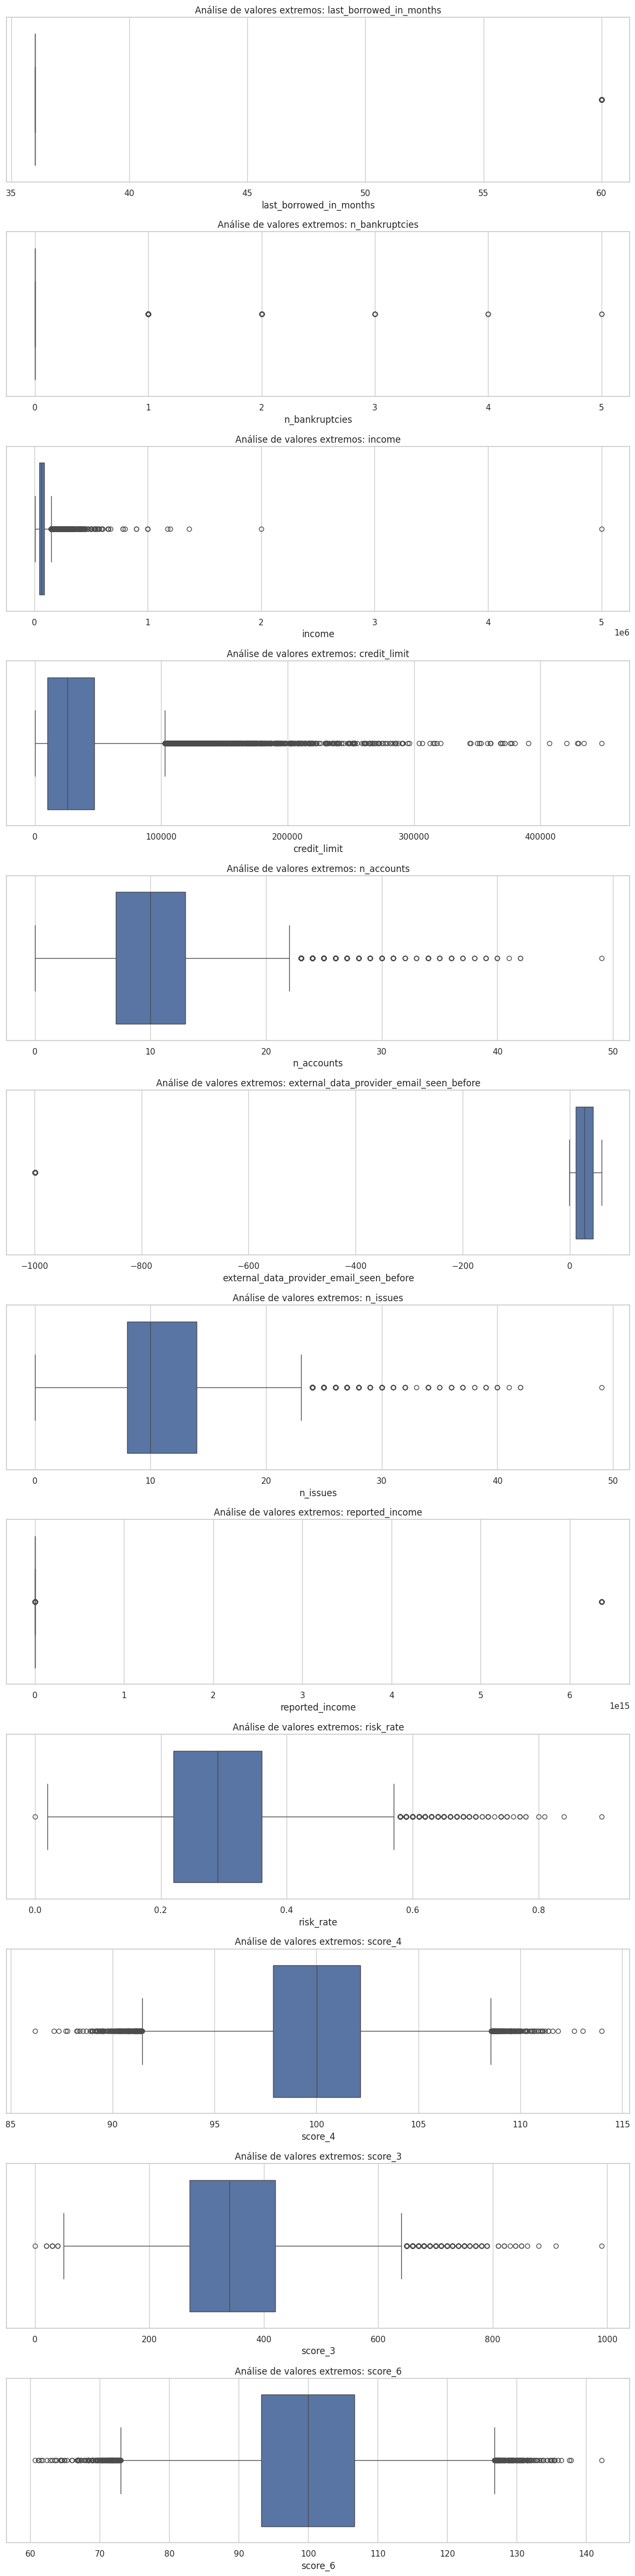

In [38]:
top_outliers = outliers.sort_values(
    'Percentual_Outliers',
    ascending=False
).head(12)['Variavel'].tolist()

fig, axes = plt.subplots(
    len(top_outliers),
    1,
    figsize=(12, 4 * len(top_outliers))
)

for ax, coluna in zip(axes, top_outliers):

    sns.boxplot(
        x=df[coluna],
        ax=ax
    )

    ax.set_title(f'Análise de valores extremos: {coluna}')

plt.tight_layout()
plt.show()

## 4.4 Investigação dos valores extremos

In [39]:
variaveis_interesse = [
    col for col in [
        'income',
        'reported_income',
        'credit_limit',
        'last_amount_borrowed',
        'risk_rate'
    ]
    if col in df.columns
]

for coluna in variaveis_interesse:

    print(f"\nMaiores valores de {coluna}")

    display(
        df[coluna]
        .nlargest(10)
        .to_frame()
    )


Maiores valores de income


,income
29646,"5,000,027.8300"
20164,"2,000,018.2000"
18767,"1,362,027.9000"
5012,"1,200,025.5600"
31405,"1,176,021.6200"
21370,"1,000,036.7300"
6435,"1,000,035.6800"
43477,"1,000,023.8700"
38556,"900,013.0800"
5191,"900,007.5800"



Maiores valores de reported_income


,reported_income
3742,inf
4002,inf
4625,inf
5438,inf
5967,inf
6382,inf
7106,inf
7429,inf
7558,inf
8117,inf



Maiores valores de credit_limit


,credit_limit
16250,"448,269.0000"
12910,"434,506.0000"
7744,"430,063.0000"
11152,"429,349.0000"
10588,"420,613.0000"
44001,"406,992.0000"
25430,"390,397.0000"
36601,"379,793.0000"
19208,"377,160.0000"
27067,"375,764.0000"



Maiores valores de last_amount_borrowed


,last_amount_borrowed
7333,"35,059.6000"
28307,"35,050.1700"
7808,"35,049.9800"
43013,"35,046.1500"
38664,"35,045.0400"
13932,"35,044.7600"
35006,"35,043.7100"
38962,"35,043.5800"
38938,"35,043.4300"
37933,"35,042.0900"



Maiores valores de risk_rate


,risk_rate
25757,0.9000
29706,0.8400
42009,0.8100
2063,0.8000
2071,0.7800
12173,0.7800
2713,0.7700
2981,0.7700
34764,0.7700
34139,0.7600


## 5. Análise de correlação
## 5.1 Matriz de correlação

In [40]:
correlacao = df[variaveis_numericas].corr(method='pearson')

display(correlacao)

,score_3,score_4,score_5,score_6,risk_rate,last_amount_borrowed,last_borrowed_in_months,credit_limit,income,ok_since,n_bankruptcies,n_defaulted_loans,n_accounts,n_issues,application_time_in_funnel,external_data_provider_credit_checks_last_2_year,external_data_provider_credit_checks_last_month,external_data_provider_credit_checks_last_year,external_data_provider_email_seen_before,external_data_provider_fraud_score,reported_income,shipping_zip_code
score_3,1.0000,-0.0017,0.0040,0.0000,0.0482,0.0417,0.0571,0.2280,-0.1115,0.0223,-0.0298,-0.0117,0.1954,0.1871,0.0038,NaN,0.0007,0.0067,0.0007,0.0014,0.0008,0.0077
score_4,-0.0017,1.0000,0.0073,0.0031,-0.0085,0.0028,0.0029,0.0027,-0.0016,0.0159,-0.0069,-0.0041,-0.0095,-0.0087,0.0020,NaN,0.0051,0.0114,-0.0064,-0.0019,0.0088,-0.0038
score_5,0.0040,0.0073,1.0000,0.0028,0.0020,-0.0021,0.0023,0.0062,-0.0046,-0.0001,0.0042,-0.0024,0.0056,0.0040,0.0065,NaN,0.0016,0.0008,-0.0082,-0.0030,-0.0036,0.0078
score_6,0.0000,0.0031,0.0028,1.0000,0.0039,0.0139,-0.0006,0.0095,0.0127,-0.0081,0.0062,0.0074,-0.0028,-0.0036,0.0004,NaN,0.0054,-0.0077,0.0054,-0.0003,0.0040,-0.0008
risk_rate,0.0482,-0.0085,0.0020,0.0039,1.0000,0.0877,0.1831,0.0016,0.0058,-0.0390,0.0305,0.0123,0.0213,0.0017,-0.0017,NaN,0.0020,0.0040,0.0032,-0.0011,-0.0028,-0.0083
last_amount_borrowed,0.0417,0.0028,-0.0021,0.0139,0.0877,1.0000,0.4170,0.2018,0.3980,-0.0400,-0.0668,0.0013,0.2035,0.1933,-0.0081,NaN,0.0023,-0.0098,0.0057,0.0186,0.0062,0.0069
last_borrowed_in_months,0.0571,0.0029,0.0023,-0.0006,0.1831,0.4170,1.0000,0.1076,0.1008,-0.0359,-0.0128,0.0024,0.0646,0.0839,0.0026,NaN,-0.0035,-0.0120,0.0021,-0.0098,0.0087,-0.0075
credit_limit,0.2280,0.0027,0.0062,0.0095,0.0016,0.2018,0.1076,1.0000,0.3042,-0.0464,-0.0407,0.0073,0.3715,0.3701,0.0026,NaN,0.0026,-0.0060,0.0083,0.0071,-0.0030,-0.0062
income,-0.1115,-0.0016,-0.0046,0.0127,0.0058,0.3980,0.1008,0.3042,1.0000,-0.0564,-0.0440,0.0137,0.1671,0.1530,-0.0063,NaN,-0.0017,0.0023,0.0061,0.0003,0.0039,-0.0040
ok_since,0.0223,0.0159,-0.0001,-0.0081,-0.0390,-0.0400,-0.0359,-0.0464,-0.0564,1.0000,0.0692,-0.0937,-0.0214,-0.0307,-0.0156,NaN,0.0002,0.0058,0.0034,0.0142,-0.0009,0.0087


## 5.2 Heatmap de correlação

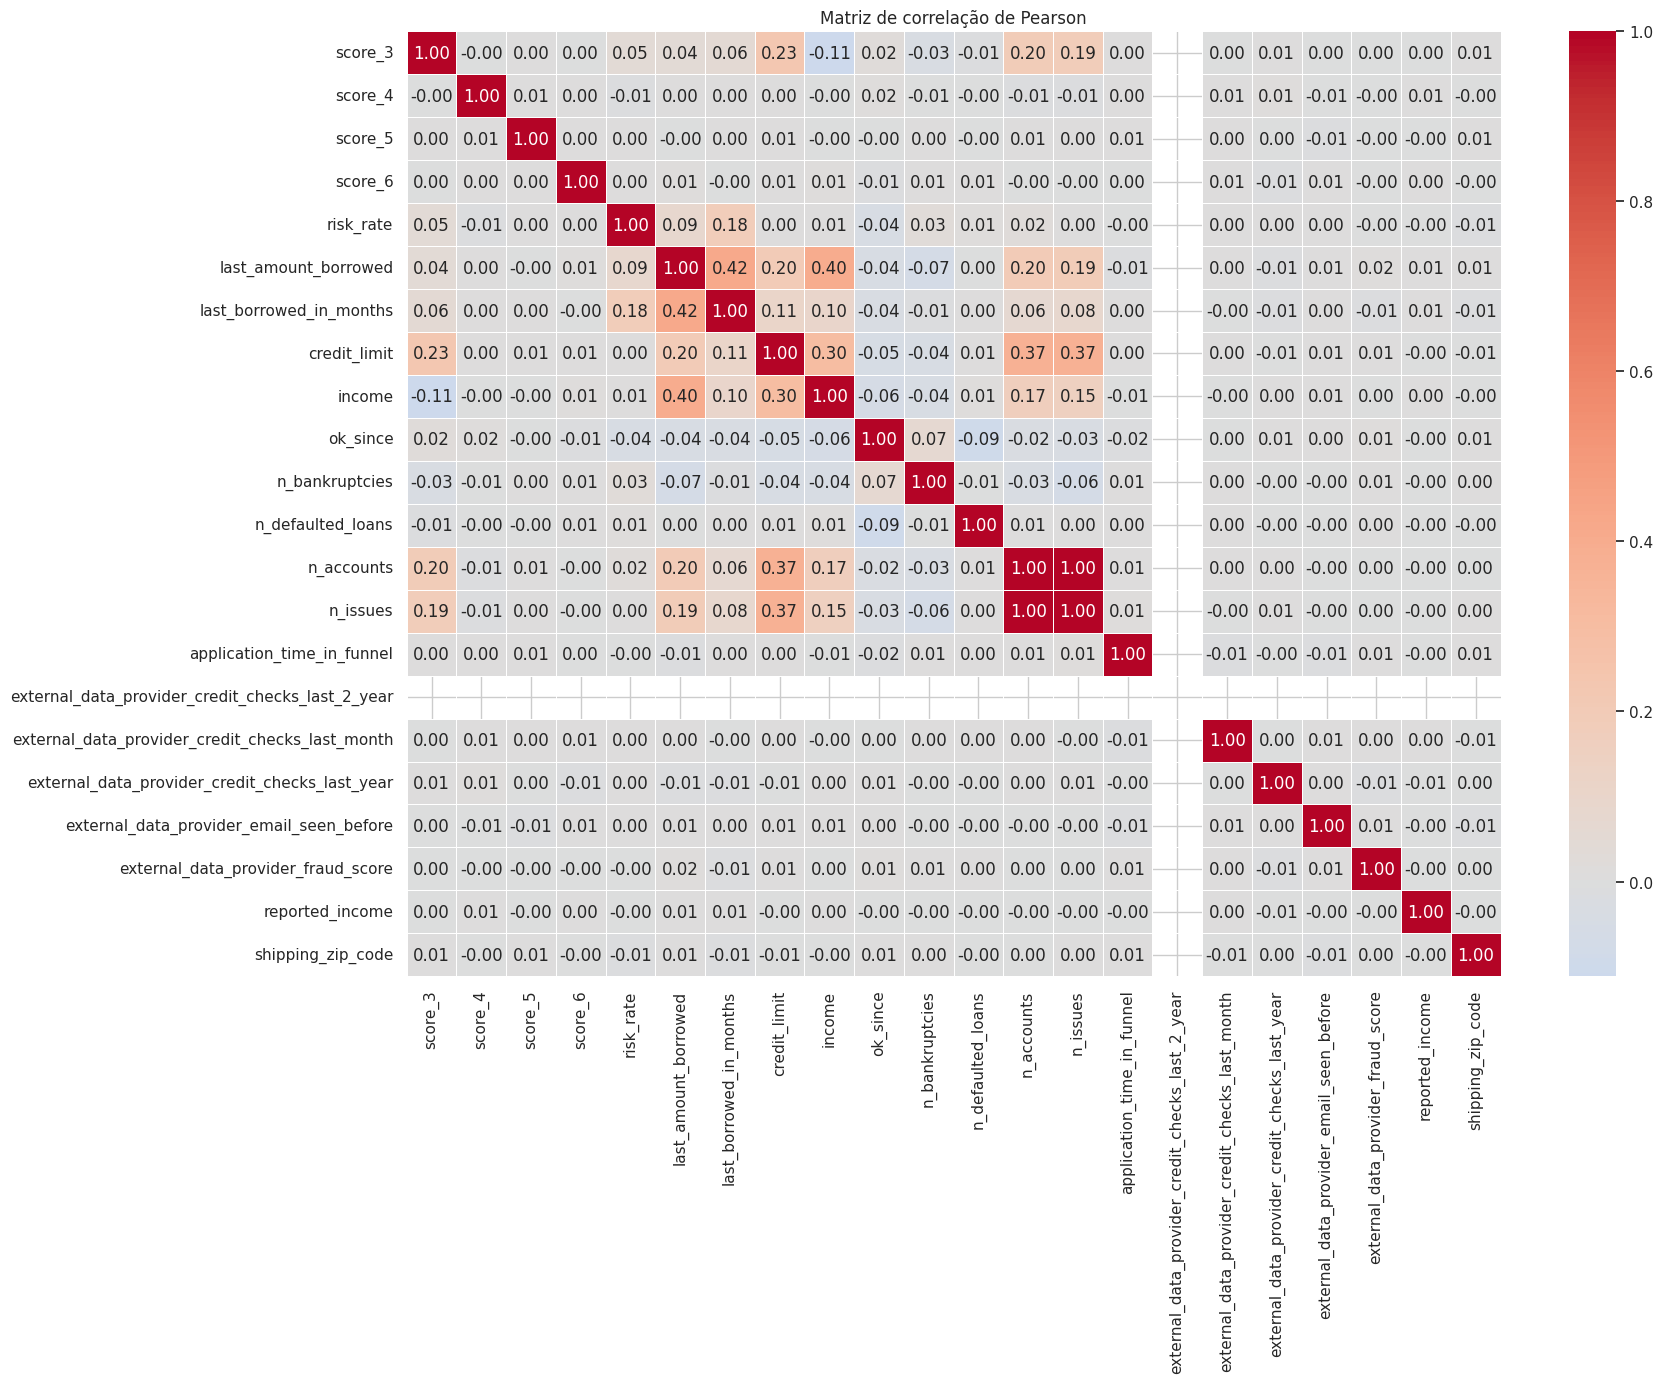

In [41]:
plt.figure(figsize=(18, 14))

sns.heatmap(
    correlacao,
    cmap='coolwarm',
    center=0,
    annot=True,
    fmt='.2f',
    linewidths=0.5
)

plt.title('Matriz de correlação de Pearson')
plt.tight_layout()
plt.show()

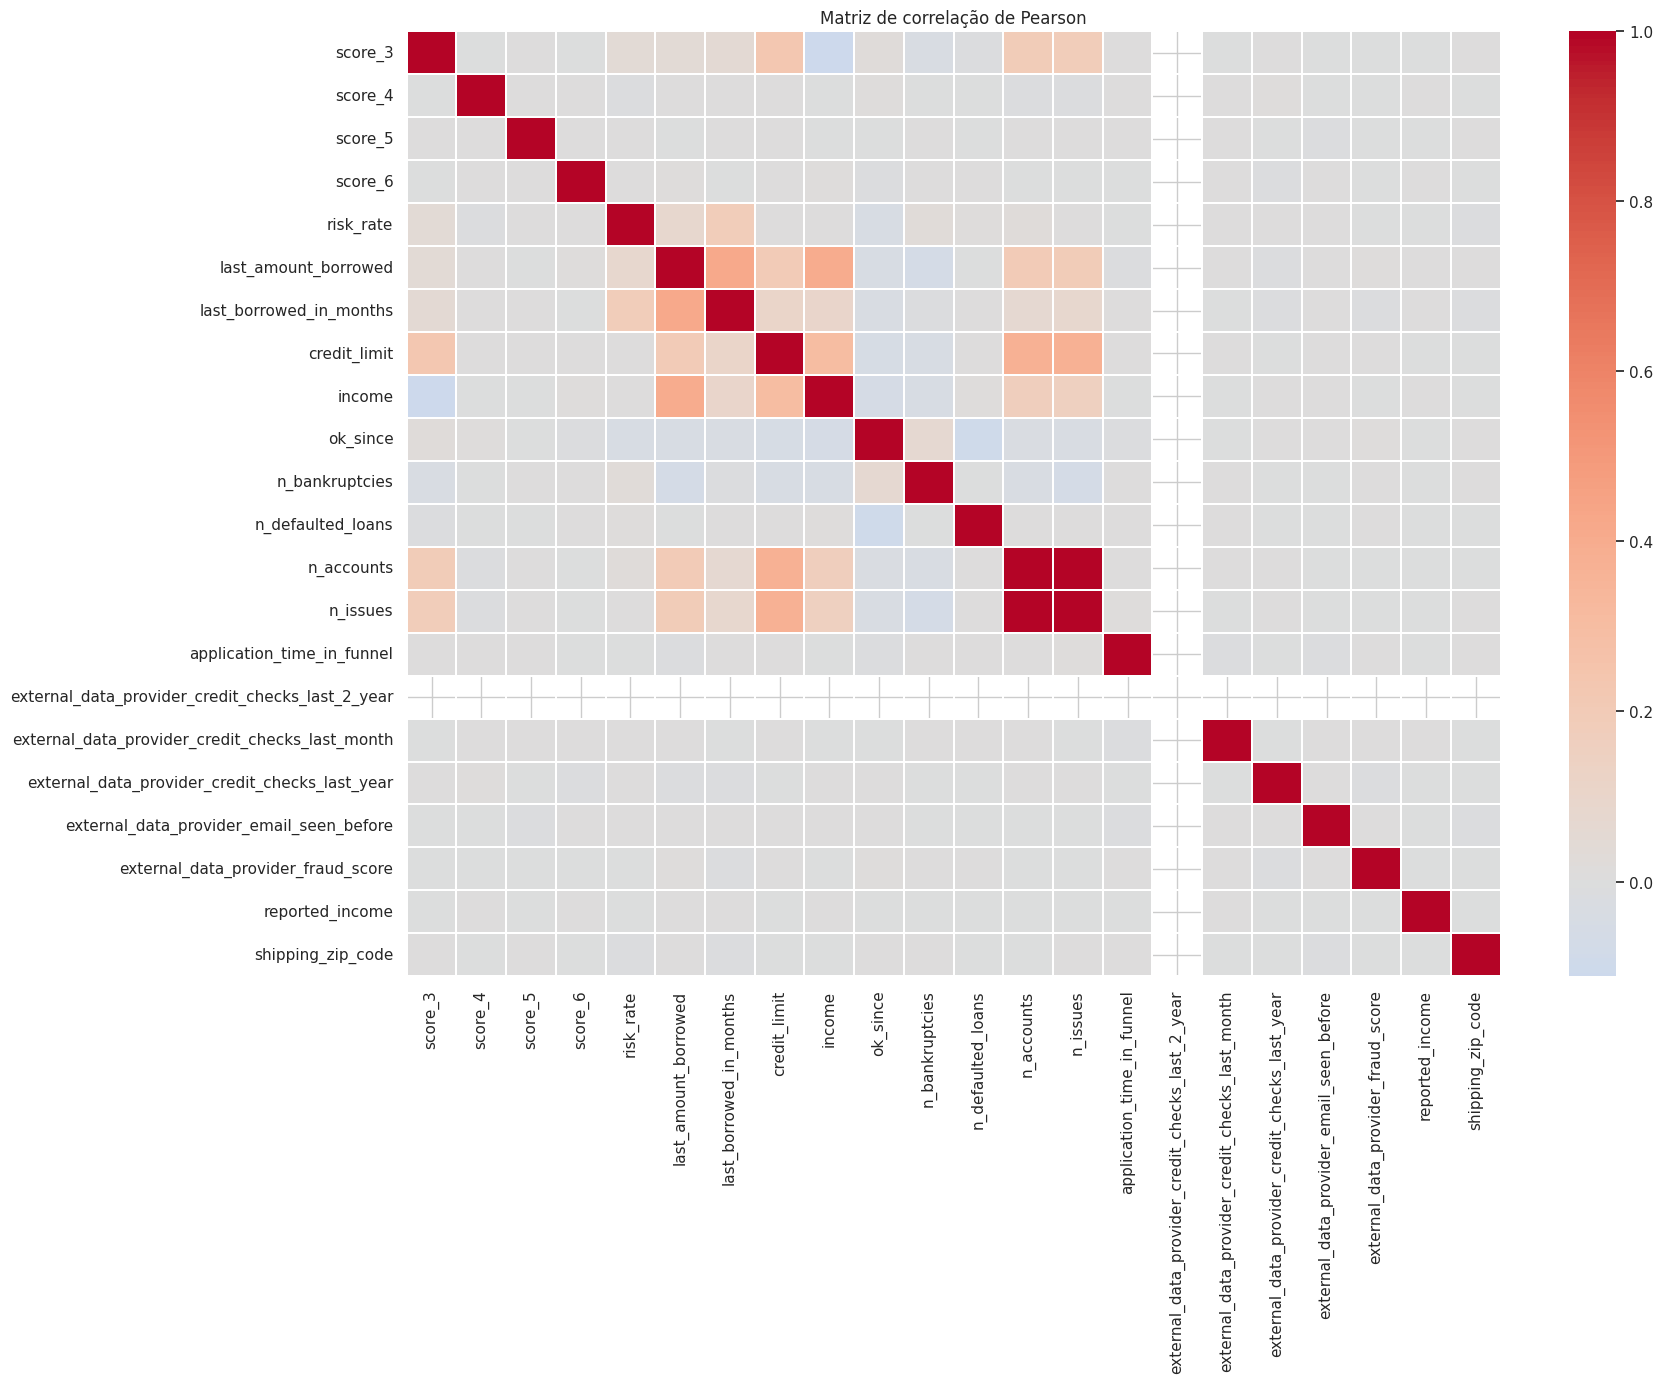

In [42]:
plt.figure(figsize=(18, 14))

sns.heatmap(
    correlacao,
    cmap='coolwarm',
    center=0,
    linewidths=0.3
)

plt.title('Matriz de correlação de Pearson')
plt.tight_layout()
plt.show()

## 5.3 Identificação de correlações elevadas

In [43]:
correlacao_abs = correlacao.abs()

mascara = np.triu(
    np.ones(correlacao_abs.shape),
    k=1
).astype(bool)

pares_correlacionados = (
    correlacao_abs.where(mascara)
    .stack()
    .reset_index()
)

pares_correlacionados.columns = [
    'Variavel_1',
    'Variavel_2',
    'Correlacao_Absoluta'
]

display(
    pares_correlacionados[
        pares_correlacionados['Correlacao_Absoluta'] >= 0.70
    ].sort_values(
        'Correlacao_Absoluta',
        ascending=False
    )
)

,Variavel_1,Variavel_2,Correlacao_Absoluta
174,n_accounts,n_issues,0.9992


## 6. Análise da variável-alvo
## 6.1 Verificação da variável-alvo

In [44]:
if 'target_default' in df.columns:

    print("Distribuição da variável target_default:")

    display(
        df['target_default']
        .value_counts(dropna=False)
        .to_frame('Frequência')
    )

    print("\nPercentual:")

    display(
        df['target_default']
        .value_counts(normalize=True, dropna=False)
        .mul(100)
        .to_frame('Percentual')
    )

Distribuição da variável target_default:


,Frequência
target_default,
False,35080
True,6661
NaN,3259



Percentual:


,Percentual
target_default,
False,77.9556
True,14.8022
NaN,7.2422


## 6.2 Visualização do desbalanceamento

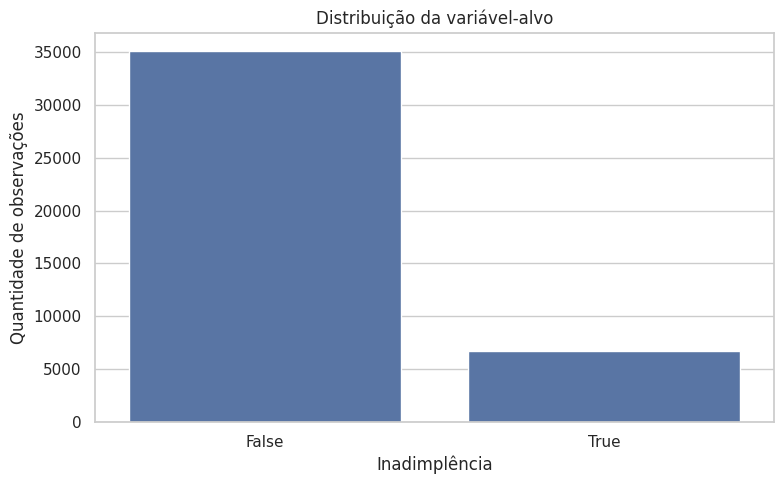

In [45]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='target_default'
)

plt.title('Distribuição da variável-alvo')
plt.xlabel('Inadimplência')
plt.ylabel('Quantidade de observações')

plt.tight_layout()
plt.show()

## 6.3 Análise das variáveis-alvo simultaneamente

In [46]:
if 'target_fraud' in df.columns:

    display(
        pd.crosstab(
            df['target_default'],
            df['target_fraud'],
            margins=True,
            normalize='index'
        )
    )

target_fraud,fraud_friends_family,fraud_id
target_default,,
False,0.3718,0.6282
True,0.7305,0.2695
All,0.6367,0.3633


## 7. Limpeza e transformação dos dados
## 7.1 Criando a base de trabalho

In [47]:
df_tratado = df_original.copy()

print("Base de trabalho criada.")
print("Dimensão inicial:", df_tratado.shape)

Base de trabalho criada.
Dimensão inicial: (45000, 43)


## 7.2 Padronização dos nomes das colunas

In [48]:
df_tratado.columns = (
    df_tratado.columns
    .str.strip()
    .str.lower()
    .str.replace(' ', '_')
)

print(df_tratado.columns.tolist())

['ids', 'target_default', 'score_1', 'score_2', 'score_3', 'score_4', 'score_5', 'score_6', 'risk_rate', 'last_amount_borrowed', 'last_borrowed_in_months', 'credit_limit', 'reason', 'income', 'facebook_profile', 'state', 'zip', 'channel', 'job_name', 'real_state', 'ok_since', 'n_bankruptcies', 'n_defaulted_loans', 'n_accounts', 'n_issues', 'application_time_applied', 'application_time_in_funnel', 'email', 'external_data_provider_credit_checks_last_2_year', 'external_data_provider_credit_checks_last_month', 'external_data_provider_credit_checks_last_year', 'external_data_provider_email_seen_before', 'external_data_provider_first_name', 'external_data_provider_fraud_score', 'lat_lon', 'marketing_channel', 'profile_phone_number', 'reported_income', 'shipping_state', 'shipping_zip_code', 'profile_tags', 'user_agent', 'target_fraud']


## 7.3 Tratamento de espaços e valores textuais

In [49]:
colunas_texto = df_tratado.select_dtypes(
    include=['object', 'string']
).columns

for coluna in colunas_texto:

    df_tratado[coluna] = (
        df_tratado[coluna]
        .astype('string')
        .str.strip()
    )

    df_tratado[coluna] = df_tratado[coluna].replace(
        ['', 'NA', 'N/A', 'NULL', 'null', 'None'],
        pd.NA
    )

print("Padronização textual concluída.")

Padronização textual concluída.


## 7.4 Verificação de duplicatas exatas

In [50]:
duplicatas_antes = df_tratado.duplicated().sum()

df_tratado = df_tratado.drop_duplicates().copy()

duplicatas_depois = df_tratado.duplicated().sum()

print("Duplicatas identificadas:", duplicatas_antes)
print("Duplicatas restantes:", duplicatas_depois)
print("Nova dimensão:", df_tratado.shape)

Duplicatas identificadas: 0
Duplicatas restantes: 0
Nova dimensão: (45000, 43)


## 7.5 Verificação dos tipos de dados

In [51]:
display(
    pd.DataFrame({
        'Tipo_Atual': df_tratado.dtypes.astype(str),
        'Valores_Nulos': df_tratado.isnull().sum(),
        'Valores_Unicos': df_tratado.nunique()
    })
)

,Tipo_Atual,Valores_Nulos,Valores_Unicos
ids,string,0,45000
target_default,string,3259,2
score_1,string,562,7
score_2,string,562,35
score_3,float64,562,88
score_4,float64,0,45000
score_5,float64,0,45000
score_6,float64,0,45000
risk_rate,float64,562,82
last_amount_borrowed,float64,29956,14325


### 7.6 Diagnóstico de variáveis codificadas e alta cardinalidade

Durante a análise da estrutura da base, foram identificadas variáveis cujos valores apresentam padrões codificados ou não interpretáveis diretamente, além de variáveis com elevada quantidade de categorias distintas.

Essas características exigem uma investigação específica, uma vez que a presença de códigos não implica necessariamente ausência de informação estatística.

O objetivo desta etapa é avaliar a natureza dessas variáveis, sua cardinalidade, frequência de ocorrência e possível contribuição para a análise de risco de crédito.

A partir desse diagnóstico, serão estabelecidos critérios para manter, transformar ou excluir variáveis, considerando sua interpretabilidade, relevância estatística, redundância e potencial de utilização nas etapas posteriores de modelagem.

## 7.6.1 Diagnóstico das variáveis

In [52]:
variaveis_codificadas = [
    'score_1',
    'score_2',
    'reason',
    'state',
    'zip',
    'channel',
    'job_name',
    'real_state'
]

diagnostico_codificadas = []

for coluna in variaveis_codificadas:

    if coluna not in df_tratado.columns:
        continue

    diagnostico_codificadas.append({
        'Variável': coluna,
        'Valores distintos': df_tratado[coluna].nunique(),
        'Valores ausentes': df_tratado[coluna].isna().sum(),
        'Percentual ausente': df_tratado[coluna].isna().mean() * 100,
        'Exemplos': df_tratado[coluna].dropna().unique()[:3].tolist()
    })

diagnostico_codificadas = pd.DataFrame(diagnostico_codificadas)

display(diagnostico_codificadas)

,Variável,Valores distintos,Valores ausentes,Percentual ausente,Exemplos
0,score_1,7,562,1.2489,"[1Rk8w4Ucd5yR3KcqZzLdow==, DGCQep2AE5QRkNCshIA..."
1,score_2,35,562,1.2489,"[IOVu8au3ISbo6+zmfnYwMg==, SaamrHMo23l/3TwXOWg..."
2,reason,14874,566,1.2578,[mLVIVxoGY7TUDJ1FyFoSIZi1SFcaBmO01AydRchaEiGYt...
3,state,50,562,1.2489,"[sjJbkqJS7cXalHLBFA+EOQ==, xsd3ZdsI3356I3xMxZe..."
4,zip,823,562,1.2489,"[Ernn+uVXCMq/6ARrBCcd+A==, rlWIXTBO+VOa34+SpGy..."
5,channel,1,562,1.2489,[NCqL3QBx0pscDnx3ixKwXg==]
6,job_name,32265,3336,7.4133,[mLVIVxoGY7TUDJ1FyFoSIZi1SFcaBmO01AydRchaEiGYt...
7,real_state,5,562,1.2489,"[N5/CE7lSkAfB04hVFFwllw==, n+xK9CfX0bCn77lClTW..."


## 7.6.2 Frequência das categorias

In [53]:
for coluna in variaveis_codificadas:

    if coluna not in df_tratado.columns:
        continue

    print(f"\n{'='*70}")
    print(f"VARIÁVEL: {coluna}")
    print(f"{'='*70}")

    display(
        df_tratado[coluna]
        .value_counts(dropna=False)
        .head(10)
        .to_frame('Frequência')
    )


VARIÁVEL: score_1


,Frequência
score_1,
DGCQep2AE5QRkNCshIAlFQ==,14523
1Rk8w4Ucd5yR3KcqZzLdow==,11376
4DLlLW62jReXaqbPaHp1vQ==,7459
8k8UDR4Yx0qasAjkGrUZLw==,6458
e4NYDor1NOw6XKGE60AWFw==,3015
smzX0nxh5QlePvtVf6EAeg==,1307
<NA>,562
fyrlulOiZ+5hoFqLa6UbDQ==,300



VARIÁVEL: score_2


,Frequência
score_2,
osCzpM4hJrxugqWWuZmMWw==,3573
SaamrHMo23l/3TwXOWgVzw==,3323
RO7MTL+j4PH2gNzbhNTq/A==,2997
/tdlnWjXoZ3OjdtBXzdOJQ==,2612
rJZgTmANW3PjOCQLCcp4iQ==,2465
Fv28Bz0YRTVAT5kl1bAV6g==,2321
7h+tk4z7O9brtBSe1rNjxA==,2309
IOVu8au3ISbo6+zmfnYwMg==,2217
LCak332j+TYFqHC3NDwiqg==,2121



VARIÁVEL: reason


,Frequência
reason,
mLVIVxoGY7TUDJ1FyFoSIZi1SFcaBmO01AydRchaEiGYtUhXGgZjtNQMnUXIWhIhmLVIVxoGY7TUDJ1FyFoSIXuusuYraWV4rGB3v/7WqHKeKq5W600DOWmwjMTqsrAW,4463
mLVIVxoGY7TUDJ1FyFoSIZi1SFcaBmO01AydRchaEiGYtUhXGgZjtNQMnUXIWhIhmLVIVxoGY7TUDJ1FyFoSIXuusuYraWV4rGB3v/7WqHIRsMoD5e3RXcnWOgQJkT1p,3090
mLVIVxoGY7TUDJ1FyFoSIZi1SFcaBmO01AydRchaEiGYtUhXGgZjtNQMnUXIWhIhmLVIVxoGY7TUDJ1FyFoSIW76/BS2rZFHqQxXY+8F9NKu9aZ57vT61+K2XFrHtvT9,1540
mLVIVxoGY7TUDJ1FyFoSIZi1SFcaBmO01AydRchaEiGYtUhXGgZjtNQMnUXIWhIhmLVIVxoGY7TUDJ1FyFoSIZi1SFcaBmO01AydRchaEiH9ooDQPWyPZgJWyjKkQUjr,1025
mLVIVxoGY7TUDJ1FyFoSIZi1SFcaBmO01AydRchaEiGYtUhXGgZjtNQMnUXIWhIhmLVIVxoGY7TUDJ1FyFoSIRd8GOItgxlRAUGKcWd5xXCeKq5W600DOWmwjMTqsrAW,898
mLVIVxoGY7TUDJ1FyFoSIZi1SFcaBmO01AydRchaEiGYtUhXGgZjtNQMnUXIWhIhmLVIVxoGY7TUDJ1FyFoSIeWE6/Di5FBOmihprdjI0zb3rnJkUI6G1sJC0+Ao35Wk,742
<NA>,566
mLVIVxoGY7TUDJ1FyFoSIZi1SFcaBmO01AydRchaEiGYtUhXGgZjtNQMnUXIWhIhmLVIVxoGY7TUDJ1FyFoSIZi1SFcaBmO01AydRchaEiFU8+AuCsj5fSH4KVfE3LF9,482
mLVIVxoGY7TUDJ1FyFoSIZi1SFcaBmO01AydRchaEiGYtUhXGgZjtNQMnUXIWhIhmLVIVxoGY7TUDJ1FyFoSIX8R4ULfEaJr602dAdoJteoyN/OiN8mDt8urzqD0fNe0,440


... (6 outputs left out)


VARIÁVEL: job_name


,Frequência
job_name,
<NA>,3336
mLVIVxoGY7TUDJ1FyFoSIZi1SFcaBmO01AydRchaEiGYtUhXGgZjtNQMnUXIWhIhmLVIVxoGY7TUDJ1FyFoSIVf4E/iI7qK+Lfl5hxoWW2A=,167
mLVIVxoGY7TUDJ1FyFoSIZi1SFcaBmO01AydRchaEiGYtUhXGgZjtNQMnUXIWhIhmLVIVxoGY7TUDJ1FyFoSIbOy82w5K5LALfp4MHskDUE=,123
mLVIVxoGY7TUDJ1FyFoSIZi1SFcaBmO01AydRchaEiGYtUhXGgZjtNQMnUXIWhIhmLVIVxoGY7TUDJ1FyFoSIaUIfpgwbYh438CvSsT5QB8=,111
mLVIVxoGY7TUDJ1FyFoSIZi1SFcaBmO01AydRchaEiGYtUhXGgZjtNQMnUXIWhIhmLVIVxoGY7TUDJ1FyFoSIfeSCTDWhw2hS0GDfQEUVwM=,78
mLVIVxoGY7TUDJ1FyFoSIZi1SFcaBmO01AydRchaEiGYtUhXGgZjtNQMnUXIWhIhmLVIVxoGY7TUDJ1FyFoSIS7jap0hM5abNdcL6dk7Ifw=,76
mLVIVxoGY7TUDJ1FyFoSIZi1SFcaBmO01AydRchaEiGYtUhXGgZjtNQMnUXIWhIhmLVIVxoGY7TUDJ1FyFoSIa6KOvl8Xp6F2JH3Vt47kH0=,70
mLVIVxoGY7TUDJ1FyFoSIZi1SFcaBmO01AydRchaEiGYtUhXGgZjtNQMnUXIWhIhmLVIVxoGY7TUDJ1FyFoSIaRr3E4aex+4Q2JdTmjOZ70=,61
mLVIVxoGY7TUDJ1FyFoSIZi1SFcaBmO01AydRchaEiGYtUhXGgZjtNQMnUXIWhIhfABZk30mT6nuzlBzfA+t9szMup/wCQYfBw/WsldHV9k=,60



VARIÁVEL: real_state


,Frequência
real_state,
N5/CE7lSkAfB04hVFFwllw==,22353
n+xK9CfX0bCn77lClTWviw==,18358
nSpvDsIsslUaX6GE6m6eQA==,3678
<NA>,562
UX7AdFYgQh+VrVC5eIaU9w==,39
+qWF9pJpVGtTFn4vFjb/cg==,10


## 7.6.3 Identificação de variáveis de cardinalidade elevada

In [54]:
cardinalidade = pd.DataFrame({
    'Variável': df_tratado.columns,
    'Valores distintos': [
        df_tratado[col].nunique(dropna=True)
        for col in df_tratado.columns
    ]
})

cardinalidade['Proporção de categorias'] = (
    cardinalidade['Valores distintos'] / len(df_tratado)
)

cardinalidade['Classificação'] = pd.cut(
    cardinalidade['Proporção de categorias'],
    bins=[-0.001, 0.01, 0.10, 0.50, 1.001],
    labels=[
        'Baixa',
        'Moderada',
        'Alta',
        'Muito alta'
    ]
)

display(
    cardinalidade.sort_values(
        'Proporção de categorias',
        ascending=False
    )
)

,Variável,Valores distintos,Proporção de categorias,Classificação
0,ids,45000,1.0000,Muito alta
5,score_4,45000,1.0000,Muito alta
6,score_5,45000,1.0000,Muito alta
7,score_6,45000,1.0000,Muito alta
36,profile_phone_number,45000,1.0000,Muito alta
13,income,41211,0.9158,Muito alta
37,reported_income,40025,0.8894,Muito alta
25,application_time_applied,35543,0.7898,Muito alta
32,external_data_provider_first_name,32886,0.7308,Muito alta
18,job_name,32265,0.7170,Muito alta


## 7.6.4 Construção da base para modelagem

In [55]:
# Criando uma cópia para a seleção de variáveis
df_modelagem = df_tratado.copy()

# Variáveis identificadoras, pessoais ou sem variabilidade
colunas_excluir = [
    'ids',
    'profile_phone_number',
    'channel'
]

# Removendo somente as variáveis previamente justificadas
df_modelagem = df_modelagem.drop(
    columns=colunas_excluir,
    errors='ignore'
)

print("Dimensão original:", df_tratado.shape)
print("Dimensão para modelagem:", df_modelagem.shape)

Dimensão original: (45000, 43)
Dimensão para modelagem: (45000, 40)


## 7.7 Conversão de variáveis de data

In [56]:
if 'application_time_applied' in df_tratado.columns:

    df_tratado['application_time_applied'] = pd.to_datetime(
        df_tratado['application_time_applied'],
        errors='coerce'
    )

    print(
        df_tratado['application_time_applied'].dtype
    )

datetime64[ns]


## 7.8 Identificação de variáveis binárias

In [57]:
variaveis_binarias = [
    coluna
    for coluna in df_tratado.columns
    if df_tratado[coluna].nunique(dropna=True) == 2
]

print("Variáveis com duas categorias:")
print(variaveis_binarias)

Variáveis com duas categorias:
['target_default', 'last_borrowed_in_months', 'facebook_profile', 'external_data_provider_credit_checks_last_year', 'target_fraud']


## 7.9 Relatório de qualidade após o tratamento inicial

In [58]:
relatorio_final = pd.DataFrame({
    'Variavel': df_tratado.columns,
    'Tipo': df_tratado.dtypes.astype(str).values,
    'Ausentes': df_tratado.isnull().sum().values,
    'Percentual_Ausente': (
        df_tratado.isnull().mean().values * 100
    ),
    'Distintos': df_tratado.nunique().values
})

display(
    relatorio_final.sort_values(
        'Percentual_Ausente',
        ascending=False
    )
)

,Variavel,Tipo,Ausentes,Percentual_Ausente,Distintos
42,target_fraud,string,43478,96.6178,2
10,last_borrowed_in_months,float64,29956,66.5689,2
9,last_amount_borrowed,float64,29956,66.5689,14325
20,ok_since,float64,26545,58.9889,100
28,external_data_provider_credit_checks_last_2_year,float64,22628,50.2844,1
30,external_data_provider_credit_checks_last_year,float64,15124,33.6089,2
11,credit_limit,float64,13800,30.6667,20928
24,n_issues,float64,11544,25.6533,44
14,facebook_profile,string,4458,9.9067,2
35,marketing_channel,string,3578,7.9511,9


## 7.10 Comparação entre a base original e a tratada

In [59]:
comparacao = pd.DataFrame({
    'Indicador': [
        'Observações',
        'Variáveis',
        'Duplicatas',
        'Valores ausentes'
    ],

    'Original': [
        df_original.shape[0],
        df_original.shape[1],
        df_original.duplicated().sum(),
        df_original.isnull().sum().sum()
    ],

    'Tratado': [
        df_tratado.shape[0],
        df_tratado.shape[1],
        df_tratado.duplicated().sum(),
        df_tratado.isnull().sum().sum()
    ]
})

display(comparacao)

,Indicador,Original,Tratado
0,Observações,45000,45000
1,Variáveis,43,43
2,Duplicatas,0,0
3,Valores ausentes,219437,222554


## 8 Exportação da base tratada

In [60]:
df_tratado.to_csv(
    'acquisition_train_tratado.csv',
    index=False
)

print("Base tratada exportada com sucesso!")

Base tratada exportada com sucesso!
